# Drought analysis for the European State of the Climate report 2023

Analysis for the spotlight section entitled 'Europe’s contrasting summer', referring to (i) the recovery of the spring drought over the Iberian Peninsula and (ii) new drought hotspots over Central and Northern Europe (see, hint in EDO report, https://joint-research-centre.ec.europa.eu/jrc-news-and-updates/variable-drought-conditions-keep-affecting-large-parts-europe-2023-07-14_en)


In [37]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cmocean
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import matplotlib.dates as mdates
from matplotlib.dates import DateFormatter
from mpl_toolkits.basemap import Basemap
from mpl_toolkits.basemap import shiftgrid
import numpy as np
import os
import datetime as dt
import pandas as pd
import geopandas as gpd
import sys
import xclim as xclim
import calendar
import netCDF4 as nc4
import xarray as xr
# create colorscheme
from dateutil import relativedelta
from datetime import timedelta
#xr.set_options(display_expand_attrs=False)

sys.path.insert(0, '..')
sys.path.insert(0, '../..')

In [38]:
from helpers.helpers import plot_spi_timeseries, plot_precip_timeseries, create_diverging_colorscheme, plot_droughtmap
from helpers.helpers_plotting import create_diverging_colorscheme
from helpers.geodata import calculate_gridarea

In [40]:
ipath         = "/scratch/nejk/droughts_hist/"
windows       = [1,3,12]
region        = "europe"
ref_period    = "1991to2020"
ryyyy_start   = int(ref_period[:4])
ryyyy_end     = int(ref_period[6:11])
print(ryyyy_start)
print(ryyyy_end)
time_period   = "20220101to20240101"

1991
2020


In [ ]:
# create colorscheme
spi_levels = [-3, -2, -1.5, -1, -0.1, 0.1, 1, 1.5, 2, 3]
plot_type  = 'pcolormesh'
cmap_spi, clevels = create_diverging_colorscheme("brown_white_green", start_color = (102/255, 51/255, 0), mid_color = (1, 1, 1), end_color = (51/255, 102/255, 0), 
                                                 levels = spi_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
color_list = [colors.rgb2hex(cmap_spi(i)) for i in range(cmap_spi.N)]
#print(color_list)

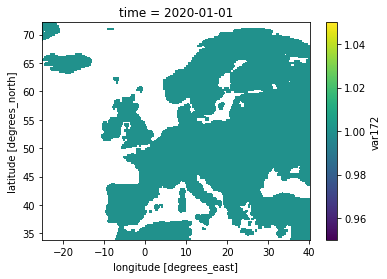

In [ ]:
# read landmask
ifile_name    = "landmask_era5_europe.nc"
ifile         = os.path.join("masks", ifile_name)
varname       = "var172"
landmask = xr.open_dataset(ifile)[varname]
landmask = landmask.where( landmask.values == 1 )
landmask.plot()

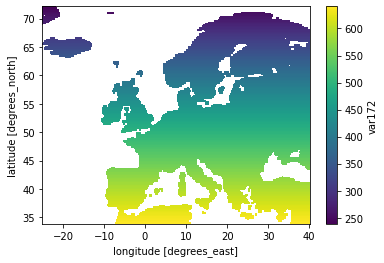

In [ ]:
area_2d = calculate_gridarea(landmask.lat, res=abs(landmask.lat[1]-landmask.lat[0]), nlon=len(landmask.lon))*landmask[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': landmask.lat,'lon': landmask.lon}, dims=["lat", "lon"])
area_2d.plot()

dict_keys(['Europe', 'Southwestern Europe', 'Northwestern Europe', 'Southeastern Europe', 'Northeastern Europe', 'Southern Europe', 'Northern Europe'])


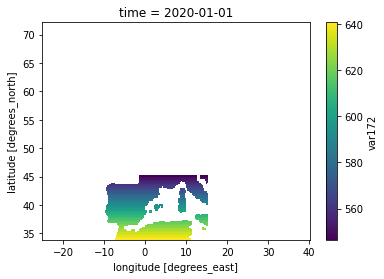

In [ ]:
# subregions (extent: W/E/S/N)
esotc_regions = {'Europe':{'extent': [-25,40,34,72], 'limits':[0,20]},    
                 'Southwestern Europe':{'extent': [-25,15,34,45], 'limits':[0,45]},    
                 'Northwestern Europe':{'extent': [-25,15,45,72], 'limits':[0,20]},    
                 'Southeastern Europe':{'extent': [15,40,34,45], 'limits':[0,45]},    
                 'Northeastern Europe':{'extent': [15,40,45,72], 'limits':[0,20]},
                 'Southern Europe':{'extent': [-25,40,34,45], 'limits':[0,45]},
                 'Northern Europe':{'extent': [-25,40,45,72], 'limits':[0,20]}}
print(esotc_regions.keys())

subregions_landmask = {}
subregions_landarea = {}
for iregion in esotc_regions.keys():

    subregions_landmask[iregion] = landmask
    mask_lon = (landmask.lon >= esotc_regions[iregion]['extent'][0]) & (landmask.lon <= esotc_regions[iregion]['extent'][1])
    mask_lat = (landmask.lat >= esotc_regions[iregion]['extent'][2]) & (landmask.lat <= esotc_regions[iregion]['extent'][3])
    subregions_landmask[iregion] = subregions_landmask[iregion].where(mask_lon & mask_lat, drop=False)

    subregions_landarea[iregion] = (subregions_landmask[iregion]*area_2d).where(mask_lon & mask_lat, drop=False)#.sum()

(subregions_landmask['Southwestern Europe']*area_2d).plot()
#(subregions_landmask['Southern Europe']*area_2d).plot()
#print(subregions_landarea['Southwestern Europe'])
#print(subregions_landarea['Southwestern Europe'].sum(dim=['lat','lon']))

In [8]:
# Read drought indicators for different accumulation periods
spi1          = xr.open_dataset(os.path.join(ipath, f"SPI1_gamma_{region}_ref{ref_period}_{time_period}.nc"))[f"SPI1"]
spi1          = spi1.where(spi1 != -9999)
spi3          = xr.open_dataset(os.path.join(ipath, f"SPI3_gamma_{region}_ref{ref_period}_{time_period}.nc"))[f"SPI3"]
spi3          = spi3.where(spi3 != -9999)
#spi3          = spi3.sel(time=slice('1960-01-01', '2023-09-01'))
spi12         = xr.open_dataset(os.path.join(ipath, f"SPI12_gamma_{region}_ref{ref_period}_{time_period}.nc"))[f"SPI12"]
spi12         = spi12.where(spi12 != -9999)

# Read drought indicators for different accumulation periods
spei1          = xr.open_dataset(os.path.join(ipath, f"SPEI1_genextreme_{region}_ref{ref_period}_{time_period}.nc"))[f"SPEI1"]
spei1          = spei1.where(spei1 != -9999)
spei3          = xr.open_dataset(os.path.join(ipath, f"SPEI3_genextreme_{region}_ref{ref_period}_{time_period}.nc"))[f"SPEI3"]
spei3          = spei3.where(spei3 != -9999)
spei12         = xr.open_dataset(os.path.join(ipath, f"SPEI12_genextreme_{region}_ref{ref_period}_{time_period}.nc"))[f"SPEI12"]
spei12         = spei12.where(spei12 != -9999)

Text(0.5, 1.0, 'SPI-3, June-July-August 2023')

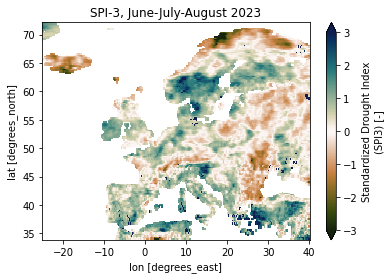

In [9]:
# test plot
spi3.sel(time="2023-08-01").plot(
    vmin=-3, vmax=3,
    cmap=cmocean.cm.tarn)
plt.title('SPI-3, June-July-August 2023')

In [10]:
area_3d     = area_2d.expand_dims(dim={"time": spi3.time}, axis=0)
landmask_3d = landmask.reindex_like(spi3, method='nearest')
#to_plot = subregions_landarea['Southwestern Europe'].reindex_like(spi3, method="nearest")
#to_plot.sel(time="2020-08-01").plot()
#print(to_plot.sum(dim=['lat','lon']))

In [11]:
aid_spi1   = {}
aid_spi3   = {}
aid_spi12  = {}
aid_spei1  = {}
aid_spei3  = {}
aid_spei12 = {}

for iregion in esotc_regions.keys():
    
    aid_spi1[iregion]   = {}
    aid_spi3[iregion]   = {}
    aid_spi12[iregion]  = {}
    aid_spei1[iregion]  = {}
    aid_spei3[iregion]  = {}
    aid_spei12[iregion] = {}
    
    for severity in ['mild','moderate','severe','extreme','any']:
    
        if severity == "mild":
            thresh_min = -1
            thresh_max = 0
        if severity == "moderate":
            thresh_min = -1.5
            thresh_max = -1
        if severity == "severe":
            thresh_min = -2
            thresh_max = -1.5
        if severity == "extreme":
            thresh_min = -999
            thresh_max = -2
        if severity == "any":
            thresh_min = -999
            thresh_max = 0

        #print(subregions_landarea[iregion].sum(dim=["lat", "lon"]))
        #print(subregions_landarea[iregion].reindex_like(spi3, method="nearest").sum(dim=["lat", "lon"]))

        # SPI
        rspi   = spi1*(subregions_landmask[iregion].reindex_like(spi1, method="nearest"))
        dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
        tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / subregions_landarea[iregion].reindex_like(rspi, method="nearest").sum(dim=["lat", "lon"])
        aid_spi1[iregion][severity] = tmp
        del(tmp, rspi, dmask)
        
        rspi   = spi3*(subregions_landmask[iregion].reindex_like(spi3, method="nearest"))
        dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
        tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / subregions_landarea[iregion].reindex_like(rspi, method="nearest").sum(dim=["lat", "lon"])
        aid_spi3[iregion][severity] = tmp
        del(tmp, rspi, dmask)
        
        rspi   = spi12*(subregions_landmask[iregion].reindex_like(spi12, method="nearest"))
        dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
        tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / subregions_landarea[iregion].reindex_like(rspi, method="nearest").sum(dim=["lat", "lon"])
        aid_spi12[iregion][severity] = tmp
        del(tmp, rspi, dmask)
        
        # SPEI
        rspi   = spei1*(subregions_landmask[iregion].reindex_like(spei1, method="nearest"))
        dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
        tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / subregions_landarea[iregion].reindex_like(rspi, method="nearest").sum(dim=["lat", "lon"])
        aid_spei1[iregion][severity] = tmp
        del(tmp, rspi, dmask)
        
        rspi   = spei3*(subregions_landmask[iregion].reindex_like(spei3, method="nearest"))
        dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
        tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / subregions_landarea[iregion].reindex_like(rspi, method="nearest").sum(dim=["lat", "lon"])
        aid_spei3[iregion][severity] = tmp
        del(tmp, rspi, dmask)
        
        rspi   = spei12*(subregions_landmask[iregion].reindex_like(spei12, method="nearest"))
        dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
        tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / subregions_landarea[iregion].reindex_like(rspi, method="nearest").sum(dim=["lat", "lon"])
        aid_spei12[iregion][severity] = tmp
        del(tmp, rspi, dmask)
        
        #lats = np.asarray(spi3.lat)
        #lons = np.asarray(spi3.lon)
        #grid_lon, grid_lat = np.meshgrid(lons, lats)
        #to_plot = np.asarray(subregions_landarea[iregion].reindex_like(spi3, method="nearest").sel(time=rspi.time[-1]).values[:])
        #to_plot = subregions_landarea[iregion].reindex_like(rspi, method="nearest")#.sel(time=rspi.time[-1])
        #to_plot.sel(time="2023-08-01").plot()
        #to_plot = dmask*area_3d
        #to_plot.sel(time="2023-08-01").plot()
        #plot_droughtmap(grid_lon, grid_lat, to_plot, 
        #                plot_type=plot_type,
        #                xlim=[-25, 40], ylim=[34, 72], zlim=[-3,3], 
        #                xlab="",ylab="",
        #                legend_title=f"{drought_index}-3", 
        #                colorscheme=cmap_spi, levels=clevels, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
        #                dfigsize=(7,7), figname='test.png')
        #to_plot = np.asarray(dmask.sel(time=dmask.time[-1]).values[:])
        #plot_droughtmap(grid_lon, grid_lat, to_plot, 
        #                plot_type=plot_type,
        #                xlim=[-25, 40], ylim=[34, 72], zlim=[-3,3], 
        #                xlab="",ylab="",
        #                legend_title=f"{drought_index}-3", 
        #                colorscheme=cmap_spi, levels=clevels, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
        #                dfigsize=(7,7), figname='test.png')

        #print(tmp[-1])
        
        #aid_spi3[iregion][severity] = tmp
        #del(tmp, rspi, dmask)

(0.0, 90.0)

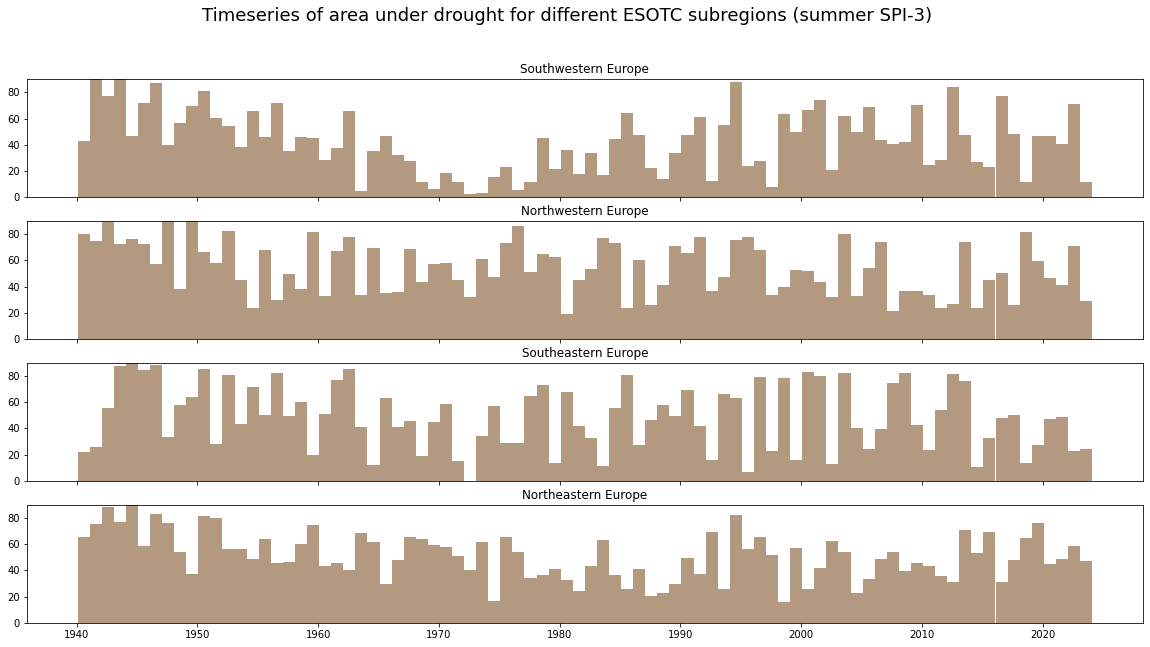

In [12]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4,1, sharex=True, figsize=(20,10), gridspec_kw={'height_ratios': [ 1.5, 1.5, 1.5, 1.5]})
fig.suptitle(f"Timeseries of area under drought for different ESOTC subregions (summer SPI-3)", fontsize=18)

severity = 'any'

iregion = list(esotc_regions.keys())[1]
pidata = aid_spi3[iregion][severity].sel(time=aid_spi3[iregion][severity].time.dt.month.isin([8])).to_series()
ax1.bar(pidata.index, pidata.values, label=iregion, width=relativedelta.relativedelta(months=12), facecolor=color_list[2], alpha=1)
ax1.set_title(iregion)
ax1.set_ylim(0,90)

iregion = list(esotc_regions.keys())[2]
pidata = aid_spi3[iregion][severity].sel(time=aid_spi3[iregion][severity].time.dt.month.isin([8])).to_series()
ax2.bar(pidata.index, pidata.values, label=iregion, width=relativedelta.relativedelta(months=12), facecolor=color_list[2], alpha=1)
ax2.set_title(iregion)
ax2.set_ylim(0,90)

iregion = list(esotc_regions.keys())[3]
pidata = aid_spi3[iregion][severity].sel(time=aid_spi3[iregion][severity].time.dt.month.isin([8])).to_series()
ax3.bar(pidata.index, pidata.values, label=iregion, width=relativedelta.relativedelta(months=12), facecolor=color_list[2], alpha=1)
ax3.set_title(iregion)
ax3.set_ylim(0,90)

iregion = list(esotc_regions.keys())[4]
pidata = aid_spi3[iregion][severity].sel(time=aid_spi3[iregion][severity].time.dt.month.isin([8])).to_series()
ax4.bar(pidata.index, pidata.values, label=iregion, width=relativedelta.relativedelta(months=12), facecolor=color_list[2], alpha=1)
ax4.set_title(iregion)
ax4.set_ylim(0,90)

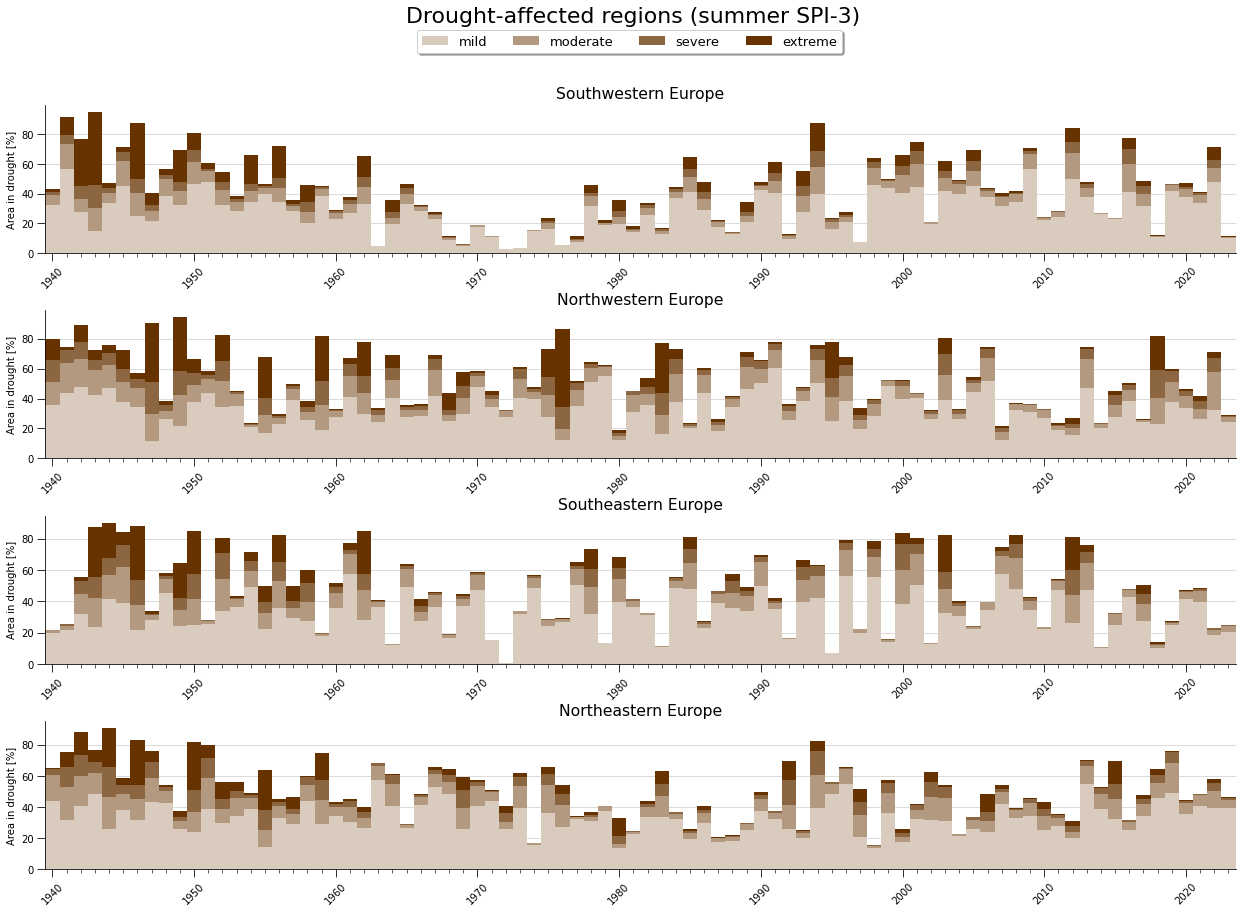

In [13]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4,1, sharex=False, figsize=(18,13), gridspec_kw={'height_ratios': [ 1.5, 1.5, 1.5, 1.5]})
fig.suptitle(f"Drought-affected regions (summer SPI-3)", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 13}

plt.rc('font', **font)

severities = ['mild','moderate','severe','extreme']

iregion = list(esotc_regions.keys())[1]
pidata1 = aid_spi3[iregion]['mild'].sel(time=aid_spi3[iregion]['mild'].time.dt.month.isin([8])).to_series()
pidata2 = aid_spi3[iregion]['moderate'].sel(time=aid_spi3[iregion]['moderate'].time.dt.month.isin([8])).to_series()
pidata3 = aid_spi3[iregion]['severe'].sel(time=aid_spi3[iregion]['severe'].time.dt.month.isin([8])).to_series()
pidata4 = aid_spi3[iregion]['extreme'].sel(time=aid_spi3[iregion]['extreme'].time.dt.month.isin([8])).to_series()
apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
bottom = np.zeros(len(apidata.index))
for i in apidata.columns:
    p = ax1.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=12), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
    bottom += apidata[i].values
ax1.set_title(iregion)
ax1.set_ylabel("Area in drought [%]")
ax1.legend(ncol=4, loc='upper right', bbox_to_anchor=(0.675, 1.55), fancybox=True, shadow=True)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
#ax1.spines['bottom'].set_visible(False)
#ax1.spines['left'].set_visible(False)  
#ax1.tick_params(axis='both', colors='dimgrey')
#ax1.xaxis.label.set_color('dimgrey')
#ax1.yaxis.label.set_color('dimgrey')
#ax1.xaxis.set_minor_locator(MultipleLocator(365)) # does not account for leap years
ax1.xaxis.set_minor_locator(mdates.YearLocator())
ax1.xaxis.set_major_locator(mdates.YearLocator(10))
date_form = DateFormatter("%Y")
ax1.xaxis.set_major_formatter(date_form)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=8)
#ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(color='lightgray', linestyle='solid') #dashed
for tick in ax1.get_xticklabels():
    tick.set_rotation(45)
    
iregion = list(esotc_regions.keys())[2]
pidata1 = aid_spi3[iregion]['mild'].sel(time=aid_spi3[iregion]['mild'].time.dt.month.isin([8])).to_series()
pidata2 = aid_spi3[iregion]['moderate'].sel(time=aid_spi3[iregion]['moderate'].time.dt.month.isin([8])).to_series()
pidata3 = aid_spi3[iregion]['severe'].sel(time=aid_spi3[iregion]['severe'].time.dt.month.isin([8])).to_series()
pidata4 = aid_spi3[iregion]['extreme'].sel(time=aid_spi3[iregion]['extreme'].time.dt.month.isin([8])).to_series()
apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
bottom = np.zeros(len(apidata.index))
for i in apidata.columns:
    p = ax2.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=12), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
    bottom += apidata[i].values
ax2.set_title(iregion)
ax2.set_ylabel("Area in drought [%]")
ax2.margins(x=0)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.xaxis.set_minor_locator(mdates.YearLocator())
ax2.xaxis.set_major_locator(mdates.YearLocator(10))
date_form = DateFormatter("%Y")
ax2.xaxis.set_major_formatter(date_form)
ax2.tick_params(which='minor', length=4)
ax2.tick_params(which='major', length=8)
ax2.set_axisbelow(True)
ax2.yaxis.grid(color='lightgray', linestyle='solid') #dashed
for tick in ax2.get_xticklabels():
    tick.set_rotation(45)
    
iregion = list(esotc_regions.keys())[3]
pidata1 = aid_spi3[iregion]['mild'].sel(time=aid_spi3[iregion]['mild'].time.dt.month.isin([8])).to_series()
pidata2 = aid_spi3[iregion]['moderate'].sel(time=aid_spi3[iregion]['moderate'].time.dt.month.isin([8])).to_series()
pidata3 = aid_spi3[iregion]['severe'].sel(time=aid_spi3[iregion]['severe'].time.dt.month.isin([8])).to_series()
pidata4 = aid_spi3[iregion]['extreme'].sel(time=aid_spi3[iregion]['extreme'].time.dt.month.isin([8])).to_series()
apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
bottom = np.zeros(len(apidata.index))
for i in apidata.columns:
    p = ax3.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=12), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
    bottom += apidata[i].values
ax3.set_title(iregion)
ax3.set_ylabel("Area in drought [%]")
ax3.margins(x=0)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.xaxis.set_minor_locator(mdates.YearLocator())
ax3.xaxis.set_major_locator(mdates.YearLocator(10))
date_form = DateFormatter("%Y")
ax3.xaxis.set_major_formatter(date_form)
ax3.tick_params(which='minor', length=4)
ax3.tick_params(which='major', length=8)
ax3.set_axisbelow(True)
ax3.yaxis.grid(color='lightgray', linestyle='solid') #dashed   
for tick in ax3.get_xticklabels():
    tick.set_rotation(45)
    
iregion = list(esotc_regions.keys())[4]
pidata1 = aid_spi3[iregion]['mild'].sel(time=aid_spi3[iregion]['mild'].time.dt.month.isin([8])).to_series()
pidata2 = aid_spi3[iregion]['moderate'].sel(time=aid_spi3[iregion]['moderate'].time.dt.month.isin([8])).to_series()
pidata3 = aid_spi3[iregion]['severe'].sel(time=aid_spi3[iregion]['severe'].time.dt.month.isin([8])).to_series()
pidata4 = aid_spi3[iregion]['extreme'].sel(time=aid_spi3[iregion]['extreme'].time.dt.month.isin([8])).to_series()
apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
bottom = np.zeros(len(apidata.index))
for i in apidata.columns:
    p = ax4.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=12), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
    bottom += apidata[i].values
ax4.set_title(iregion)
ax4.set_ylabel("Area in drought [%]")
ax4.margins(x=0)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.xaxis.set_minor_locator(mdates.YearLocator())
ax4.xaxis.set_major_locator(mdates.YearLocator(10))
date_form = DateFormatter("%Y")
ax4.xaxis.set_major_formatter(date_form)
ax4.tick_params(which='minor', length=4)
ax4.tick_params(which='major', length=8)
ax4.set_axisbelow(True)
ax4.yaxis.grid(color='lightgray', linestyle='solid') #dashed
for tick in ax4.get_xticklabels():
    tick.set_rotation(45)

Processing SPI-1...


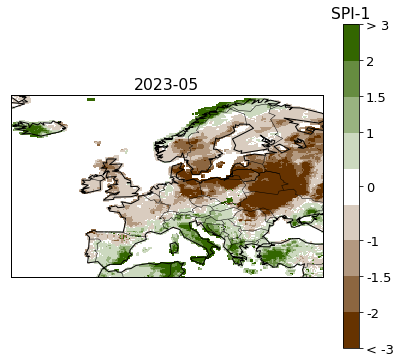

Processing SPI-1...


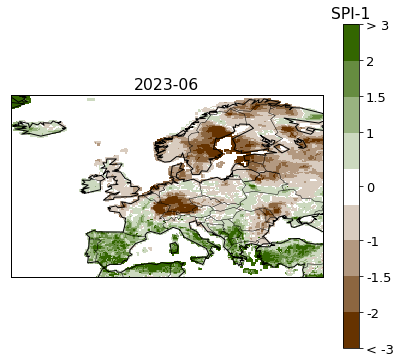

Processing SPI-1...


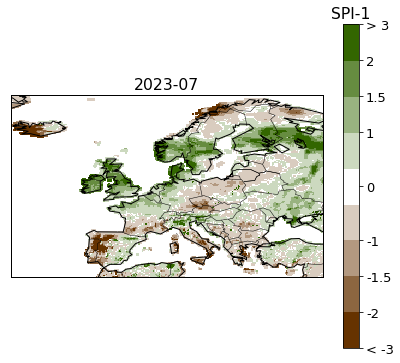

Processing SPI-1...


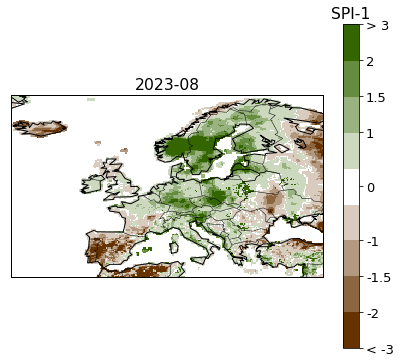

Processing SPI-1...


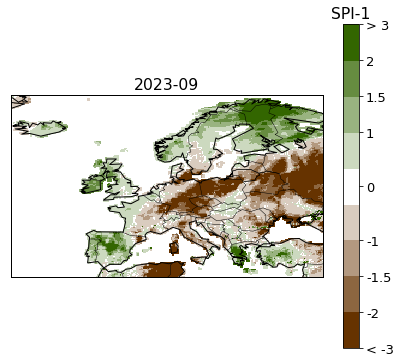

Processing SPI-3...


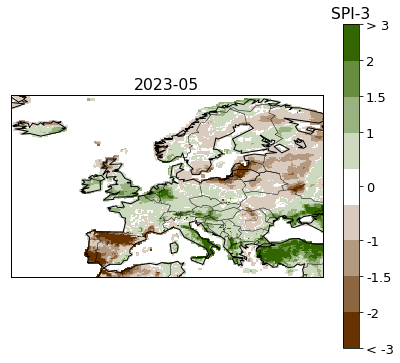

Processing SPI-3...


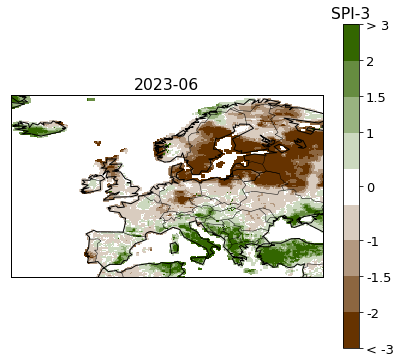

Processing SPI-3...


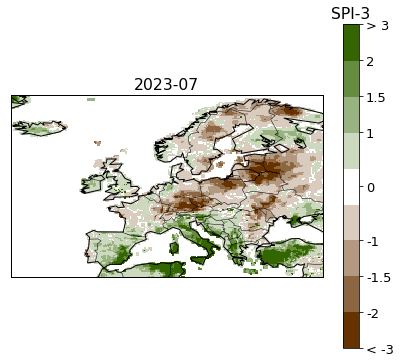

Processing SPI-3...


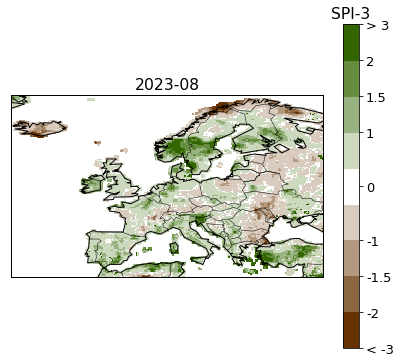

Processing SPI-3...


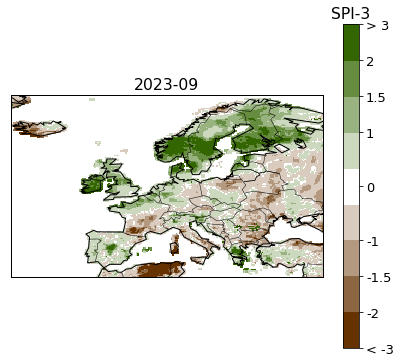

In [14]:
lats = np.asarray(spi3.lat)
lons = np.asarray(spi3.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)
    
for itime in range(len(spi1.time))[-5:]:

    print(f"Processing SPI-1...")

    stime = spi1.time.dt.strftime('%Y-%m').values[:][itime]
    ytime = spi1.time.dt.strftime('%Y').values[:][itime]

    # plot
    figname = f"figures/esotc_2023_spotlight/Droughtmap_Europe_SPI-1_{stime}.png"
    to_plot = np.asarray(spi1.sel(time=spi1.time[itime]).values[:])
    plot_droughtmap(grid_lon, grid_lat, to_plot, 
                    plot_type=plot_type,
                    xlim=[-25, 40], ylim=[34, 72], zlim=[-3,3], 
                    xlab="",ylab="",
                    main_title=f"{stime}", legend_title=f"SPI-1", 
                    colorscheme=cmap_spi, levels=clevels, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
                    dfigsize=(7,7), figname=figname)

    #figname = f"Droughtmap_Europe_{drought_index}-1_{stime}.png"
    #plt.savefig(figname, dpi='figure', format=None, metadata=None,
    #        bbox_inches=None, pad_inches=0.1,
    #        facecolor='auto', edgecolor='auto',
    #        backend=None)
    
for itime in range(len(spi3.time))[-5:]:

    print(f"Processing SPI-3...")

    stime = spi3.time.dt.strftime('%Y-%m').values[:][itime]
    ytime = spi3.time.dt.strftime('%Y').values[:][itime]

    # plot
    figname = f"figures/esotc_2023_spotlight/Droughtmap_Europe_SPI-3_{stime}.png"
    to_plot = np.asarray(spi3.sel(time=spi3.time[itime]).values[:])
    plot_droughtmap(grid_lon, grid_lat, to_plot, 
                    plot_type=plot_type,
                    xlim=[-25, 40], ylim=[34, 72], zlim=[-3,3], 
                    xlab="",ylab="",
                    main_title=f"{stime}", legend_title=f"SPI-3", 
                    colorscheme=cmap_spi, levels=clevels, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
                    dfigsize=(7,7), figname=figname)

    #figname = f"Droughtmap_Europe_{drought_index}-3_{stime}.png"
    #plt.savefig(figname, dpi='figure', format=None, metadata=None,
    #        bbox_inches=None, pad_inches=0.1,
    #        facecolor='auto', edgecolor='auto',
    #        backend=None)
    

In [15]:
#for imonth in [6,7,8]:
def plot_timeseries_aid_severity(aid_index, imonth, barwidth_months=12, shiftmonths=-7, mytitle=f"Drought-affected regions"):

    fig, (ax1, ax2, ax3, ax4) = plt.subplots(4,1, sharex=False, figsize=(18,13), gridspec_kw={'height_ratios': [ 1.5, 1.5, 1.5, 1.5]})
    fig.suptitle(mytitle, fontsize=22)
    fig.tight_layout(pad=3.75)
    fig.subplots_adjust(top=0.875)
    font = {'family' : 'sans-serif',
            'weight' : 'normal',
            'size'   : 13}

    plt.rc('font', **font)

    severities = ['mild','moderate','severe','extreme']

    iregion = list(esotc_regions.keys())[1]
    pidata1 = aid_index[iregion]['mild'].sel(time=aid_index[iregion]['mild'].time.dt.month.isin([imonth])).to_series()
    pidata2 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.month.isin([imonth])).to_series()
    pidata3 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.month.isin([imonth])).to_series()
    pidata4 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.month.isin([imonth])).to_series()
    apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
    apidata.index = apidata.index.shift(shiftmonths, freq="MS") # shift datetimeindex to get ticks centered on bar
    bottom = np.zeros(len(apidata.index))
    for i in apidata.columns:
        p = ax1.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=barwidth_months), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
        bottom += apidata[i].values
    ax1.set_title(iregion)
    ax1.set_ylabel("Area in drought [%]")
    ax1.legend(ncol=4, loc='upper right', bbox_to_anchor=(0.675, 1.55), fancybox=True, shadow=True)
    ax1.margins(x=0)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    #ax1.spines['bottom'].set_visible(False)
    #ax1.spines['left'].set_visible(False)  
    #ax1.tick_params(axis='both', colors='dimgrey')
    #ax1.xaxis.label.set_color('dimgrey')
    #ax1.yaxis.label.set_color('dimgrey')
    #ax1.xaxis.set_minor_locator(MultipleLocator(365)) # does not account for leap years
    ax1.xaxis.set_minor_locator(mdates.YearLocator())
    ax1.xaxis.set_major_locator(mdates.YearLocator(10))
    date_form = DateFormatter("%Y")
    ax1.xaxis.set_major_formatter(date_form)
    ax1.tick_params(which='minor', length=4)
    ax1.tick_params(which='major', length=8)
    #ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
    #ax1.grid(True)
    ax1.set_axisbelow(True)
    ax1.yaxis.grid(color='lightgray', linestyle='solid') #dashed
    for tick in ax1.get_xticklabels():
        tick.set_rotation(45)

    iregion = list(esotc_regions.keys())[2]
    pidata1 = aid_index[iregion]['mild'].sel(time=aid_index[iregion]['mild'].time.dt.month.isin([imonth])).to_series()
    pidata2 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.month.isin([imonth])).to_series()
    pidata3 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.month.isin([imonth])).to_series()
    pidata4 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.month.isin([imonth])).to_series()
    apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
    apidata.index = apidata.index.shift(shiftmonths, freq="MS") # shift datetimeindex to get ticks centered on bar
    bottom = np.zeros(len(apidata.index))
    for i in apidata.columns:
        p = ax2.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=barwidth_months), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
        bottom += apidata[i].values
    ax2.set_title(iregion)
    ax2.set_ylabel("Area in drought [%]")
    ax2.margins(x=0)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.xaxis.set_minor_locator(mdates.YearLocator())
    ax2.xaxis.set_major_locator(mdates.YearLocator(10))
    date_form = DateFormatter("%Y")
    ax2.xaxis.set_major_formatter(date_form)
    ax2.tick_params(which='minor', length=4)
    ax2.tick_params(which='major', length=8)
    ax2.set_axisbelow(True)
    ax2.yaxis.grid(color='lightgray', linestyle='solid') #dashed
    for tick in ax2.get_xticklabels():
        tick.set_rotation(45)

    iregion = list(esotc_regions.keys())[3]
    pidata1 = aid_index[iregion]['mild'].sel(time=aid_index[iregion]['mild'].time.dt.month.isin([imonth])).to_series()
    pidata2 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.month.isin([imonth])).to_series()
    pidata3 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.month.isin([imonth])).to_series()
    pidata4 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.month.isin([imonth])).to_series()
    apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
    apidata.index = apidata.index.shift(shiftmonths, freq="MS") # shift datetimeindex to get ticks centered on bar
    bottom = np.zeros(len(apidata.index))
    for i in apidata.columns:
        p = ax3.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=barwidth_months), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
        bottom += apidata[i].values
    ax3.set_title(iregion)
    ax3.set_ylabel("Area in drought [%]")
    ax3.margins(x=0)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    ax3.xaxis.set_minor_locator(mdates.YearLocator())
    ax3.xaxis.set_major_locator(mdates.YearLocator(10))
    date_form = DateFormatter("%Y")
    ax3.xaxis.set_major_formatter(date_form)
    ax3.tick_params(which='minor', length=4)
    ax3.tick_params(which='major', length=8)
    ax3.set_axisbelow(True)
    ax3.yaxis.grid(color='lightgray', linestyle='solid') #dashed   
    for tick in ax3.get_xticklabels():
        tick.set_rotation(45)

    iregion = list(esotc_regions.keys())[4]
    pidata1 = aid_index[iregion]['mild'].sel(time=aid_index[iregion]['mild'].time.dt.month.isin([imonth])).to_series()
    pidata2 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.month.isin([imonth])).to_series()
    pidata3 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.month.isin([imonth])).to_series()
    pidata4 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.month.isin([imonth])).to_series()
    apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
    apidata.index = apidata.index.shift(shiftmonths, freq="MS") # shift datetimeindex to get ticks centered on bar
    bottom = np.zeros(len(apidata.index))
    for i in apidata.columns:
        p = ax4.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=barwidth_months), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
        bottom += apidata[i].values
    ax4.set_title(iregion)
    ax4.set_ylabel("Area in drought [%]")
    ax4.margins(x=0)
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)
    ax4.xaxis.set_minor_locator(mdates.YearLocator())
    ax4.xaxis.set_major_locator(mdates.YearLocator(10))
    date_form = DateFormatter("%Y")
    ax4.xaxis.set_major_formatter(date_form)
    ax4.tick_params(which='minor', length=4)
    ax4.tick_params(which='major', length=8)
    ax4.set_axisbelow(True)
    ax4.yaxis.grid(color='lightgray', linestyle='solid') #dashed
    for tick in ax4.get_xticklabels():
        tick.set_rotation(45)

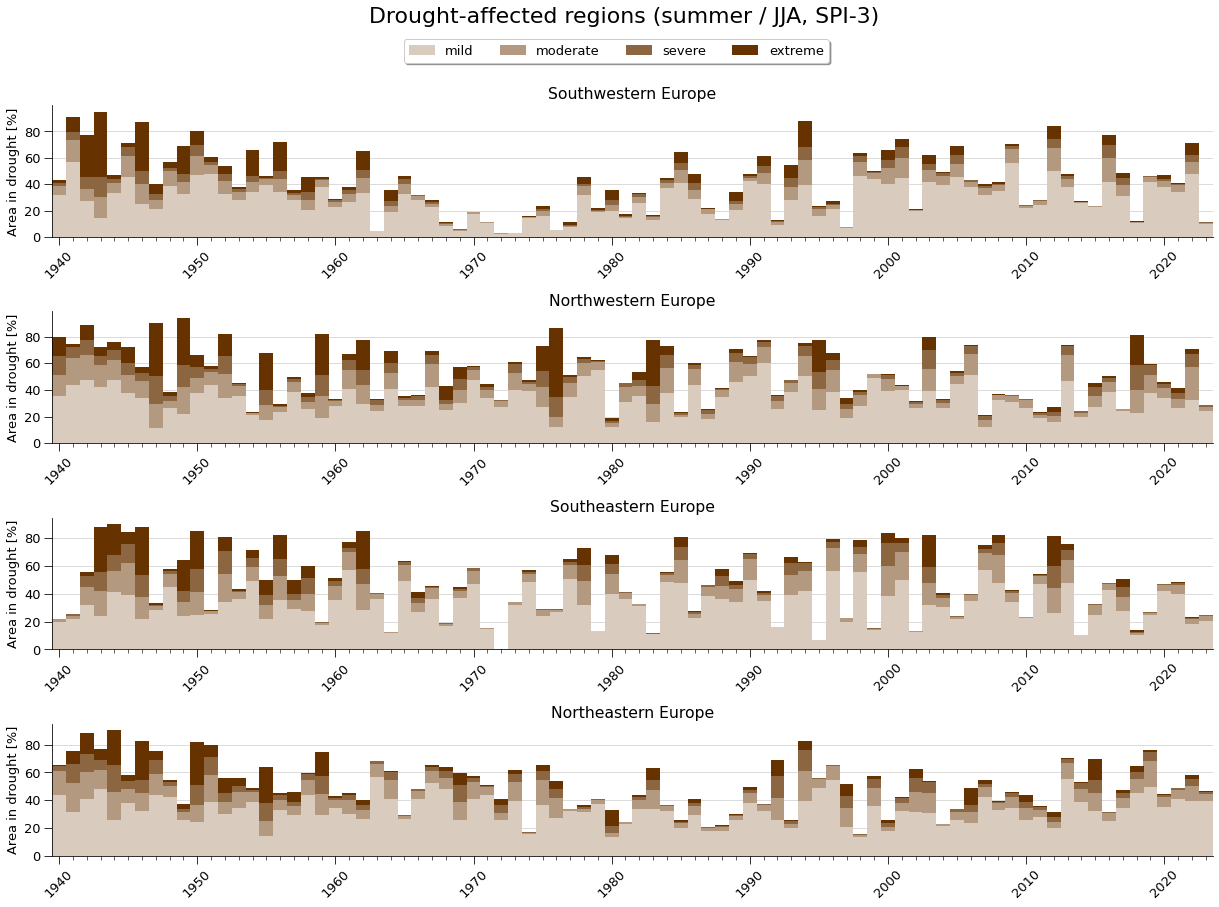

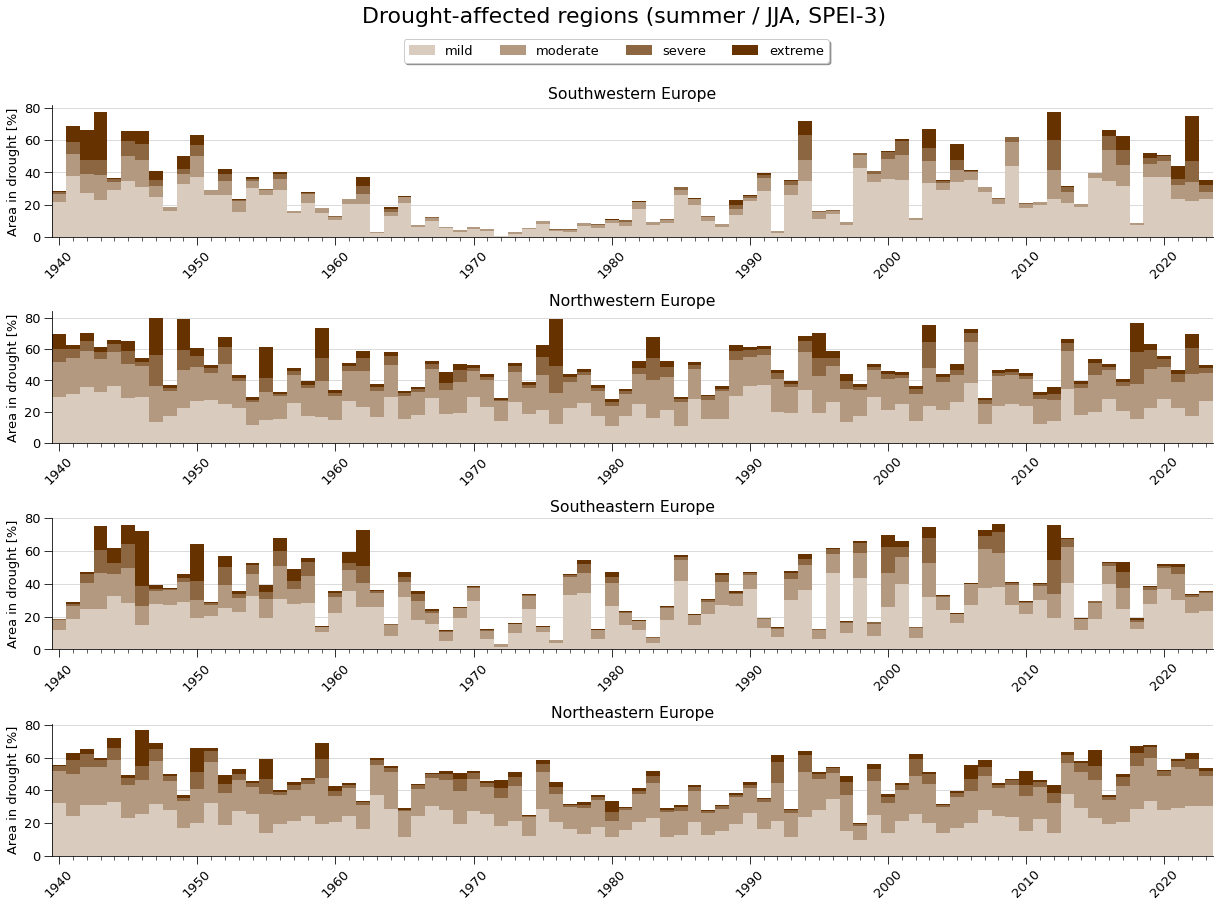

In [19]:
plot_timeseries_aid_severity(aid_spi3, 8, barwidth_months=12, shiftmonths=-7, mytitle=f"Drought-affected regions (summer / JJA, SPI-3)")
plot_timeseries_aid_severity(aid_spei3, 8, barwidth_months=12, shiftmonths=-7, mytitle=f"Drought-affected regions (summer / JJA, SPEI-3)")

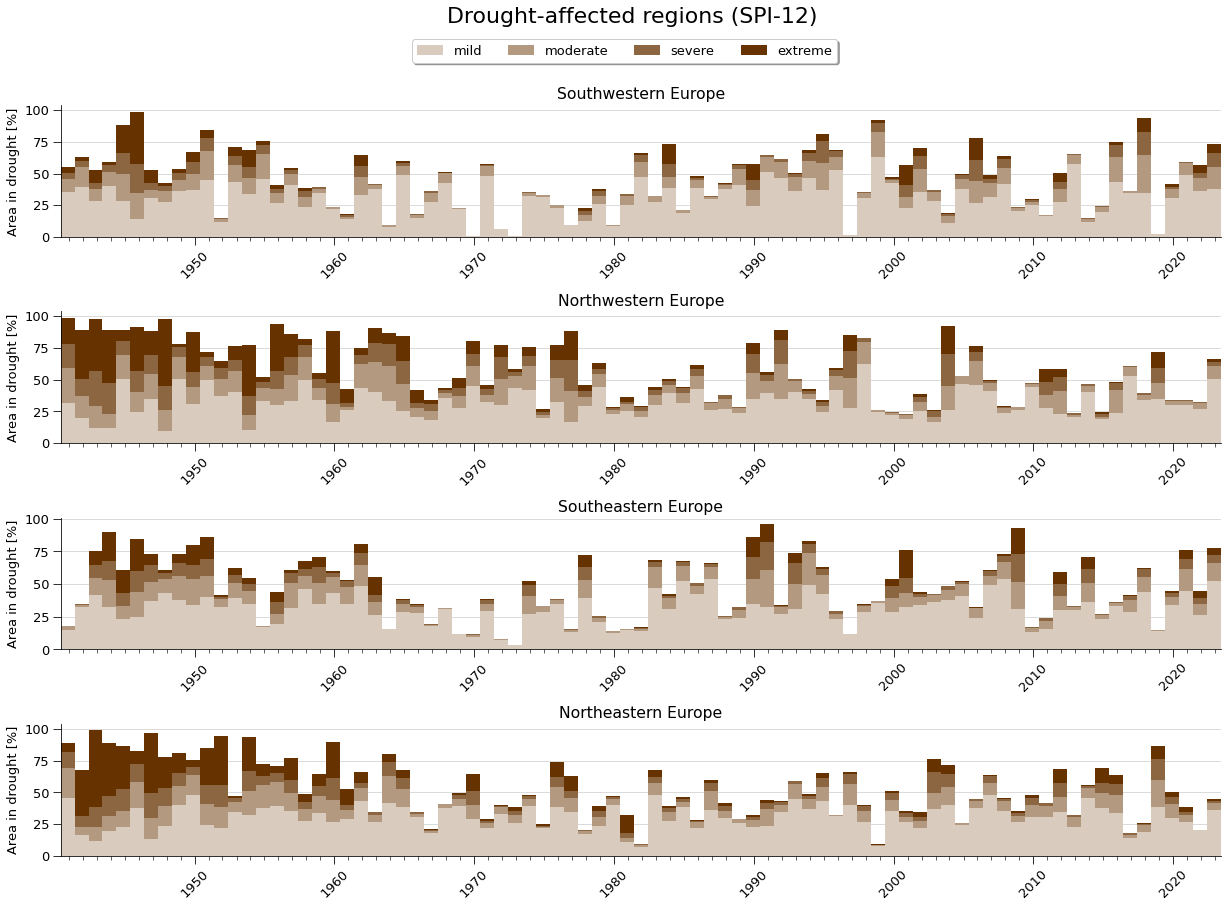

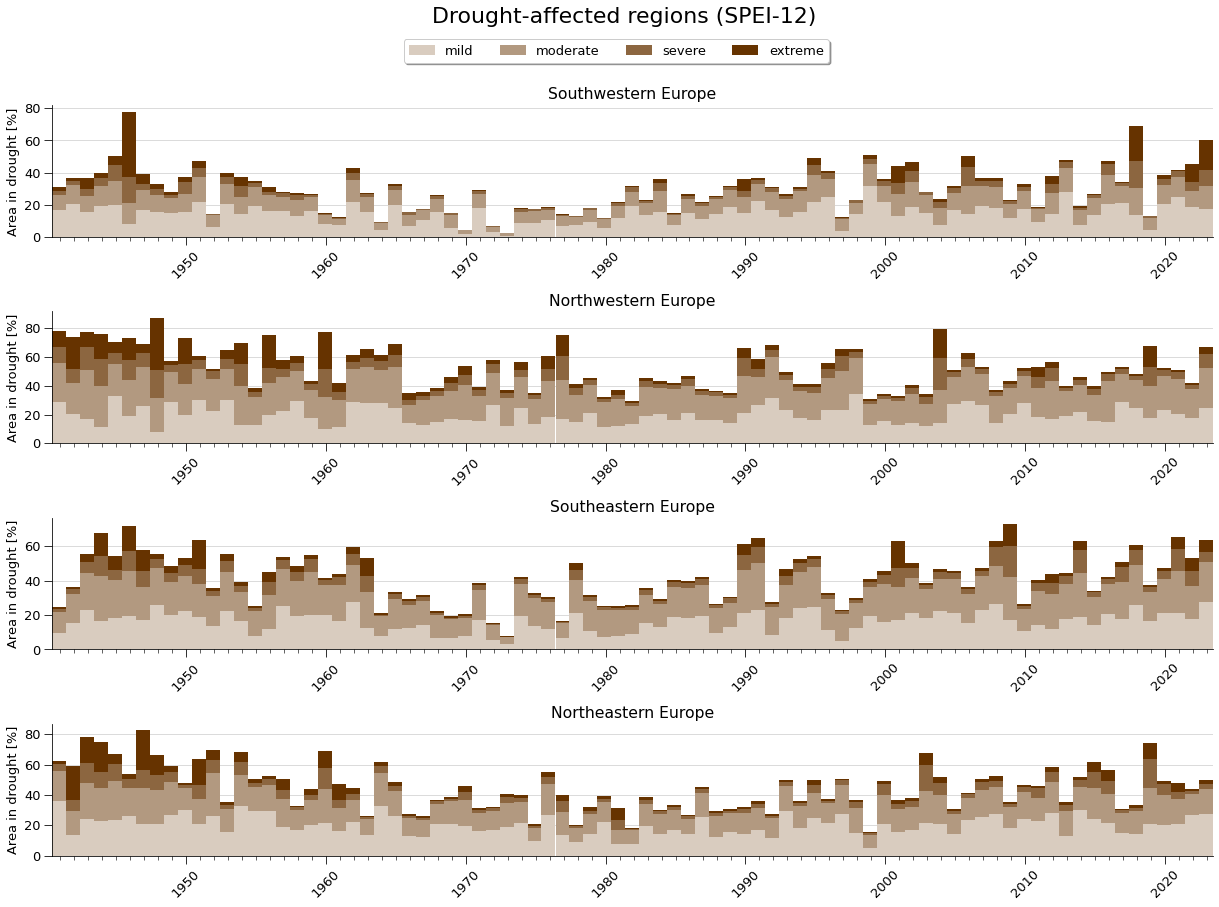

In [20]:
plot_timeseries_aid_severity(aid_spi12, 12, barwidth_months=12, shiftmonths=0, mytitle=f"Drought-affected regions (SPI-12)")
plot_timeseries_aid_severity(aid_spei12, 12, barwidth_months=12, shiftmonths=0, mytitle=f"Drought-affected regions (SPEI-12)")

In [21]:
def plot_annual_cycle_aid_subregions_bars(aid_index, selyear=2023):

    fig, (ax1, ax2, ax3, ax4) = plt.subplots(4,1, sharex=False, figsize=(12,13), gridspec_kw={'height_ratios': [ 1.5, 1.5, 1.5, 1.5]})

    fig.suptitle(f"Drought-affected regions ({selyear})", fontsize=22)
    fig.tight_layout(pad=3.75)
    fig.subplots_adjust(top=0.875)
    font = {'family' : 'sans-serif',
            'weight' : 'normal',
            'size'   : 13}
    plt.rc('font', **font)

    severities = ['mild','moderate','severe','extreme']

    iregion = list(esotc_regions.keys())[1]
    pidata1 = aid_index[iregion]['mild'].sel(time=aid_index[iregion]['mild'].time.dt.year.isin([selyear])).to_series()
    pidata2 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([selyear])).to_series()
    pidata3 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([selyear])).to_series()
    pidata4 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([selyear])).to_series()
    apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
    bottom = np.zeros(len(apidata.index))
    for i in apidata.columns:
        p = ax1.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(days=15), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
        bottom += apidata[i].values
    ax1.set_title(iregion)
    ax1.set_ylabel("Area in drought [%]")
    ax1.legend(ncol=4, loc='upper right', bbox_to_anchor=(0.775, 1.55), fancybox=True, shadow=True)
    ax1.margins(x=0)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.set_axisbelow(True)
    ax1.yaxis.grid(color='lightgray', linestyle='solid') #dashed
    for tick in ax1.get_xticklabels():
        tick.set_rotation(45)


    iregion = list(esotc_regions.keys())[2]
    pidata1 = aid_index[iregion]['mild'].sel(time=aid_index[iregion]['mild'].time.dt.year.isin([selyear])).to_series()
    pidata2 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([selyear])).to_series()
    pidata3 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([selyear])).to_series()
    pidata4 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([selyear])).to_series()
    apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
    bottom = np.zeros(len(apidata.index))
    for i in apidata.columns:
        p = ax2.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(days=15), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
        bottom += apidata[i].values
    ax2.set_title(iregion)
    ax2.set_ylabel("Area in drought [%]")
    ax2.margins(x=0)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.set_axisbelow(True)
    ax2.yaxis.grid(color='lightgray', linestyle='solid') #dashed
    for tick in ax2.get_xticklabels():
        tick.set_rotation(45)


    iregion = list(esotc_regions.keys())[3]
    pidata1 = aid_index[iregion]['mild'].sel(time=aid_index[iregion]['mild'].time.dt.year.isin([selyear])).to_series()
    pidata2 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([selyear])).to_series()
    pidata3 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([selyear])).to_series()
    pidata4 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([selyear])).to_series()
    apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
    #apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
    bottom = np.zeros(len(apidata.index))
    for i in apidata.columns:
        p = ax3.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(days=15), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
        bottom += apidata[i].values
    ax3.set_title(iregion)
    ax3.set_ylabel("Area in drought [%]")
    ax3.margins(x=0)
    ax3.spines['top'].set_visible(False)
    ax3.spines['right'].set_visible(False)
    ax3.set_axisbelow(True)
    ax3.yaxis.grid(color='lightgray', linestyle='solid') #dashed
    for tick in ax3.get_xticklabels():
        tick.set_rotation(45)


    iregion = list(esotc_regions.keys())[4]
    pidata1 = aid_index[iregion]['mild'].sel(time=aid_index[iregion]['mild'].time.dt.year.isin([selyear])).to_series()
    pidata2 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([selyear])).to_series()
    pidata3 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([selyear])).to_series()
    pidata4 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([selyear])).to_series()
    apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
    #apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
    bottom = np.zeros(len(apidata.index))
    for i in apidata.columns:
        p = ax4.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(days=15), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
        bottom += apidata[i].values
    ax4.set_title(iregion)
    ax4.set_ylabel("Area in drought [%]")
    ax4.margins(x=0)
    ax4.spines['top'].set_visible(False)
    ax4.spines['right'].set_visible(False)
    ax4.set_axisbelow(True)
    ax4.yaxis.grid(color='lightgray', linestyle='solid') #dashed
    for tick in ax4.get_xticklabels():
        tick.set_rotation(45)

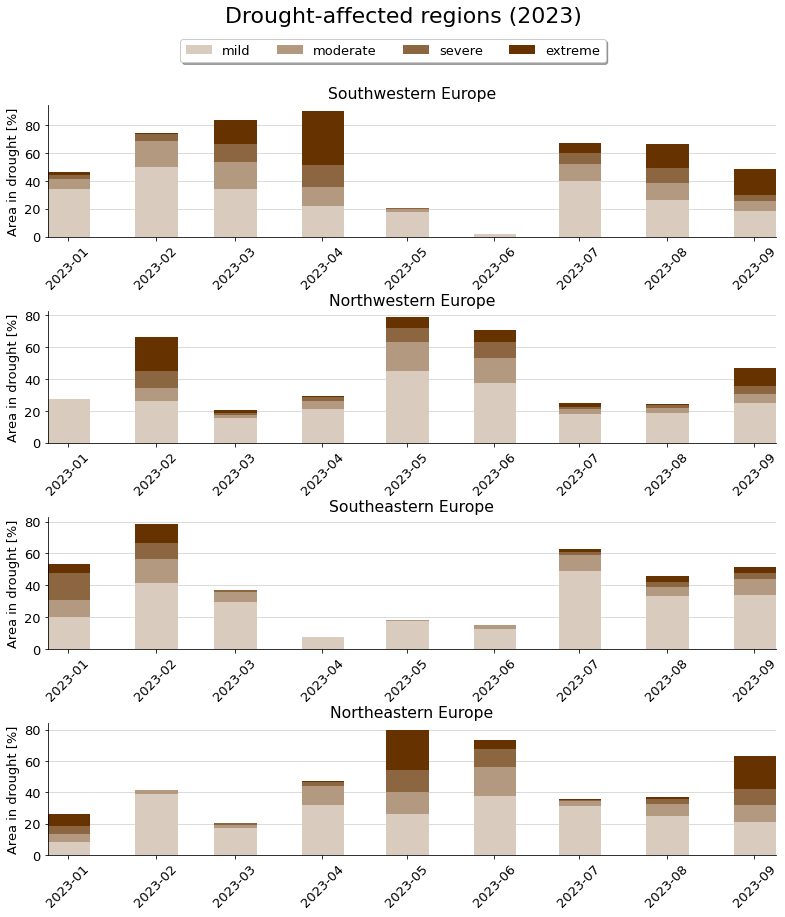

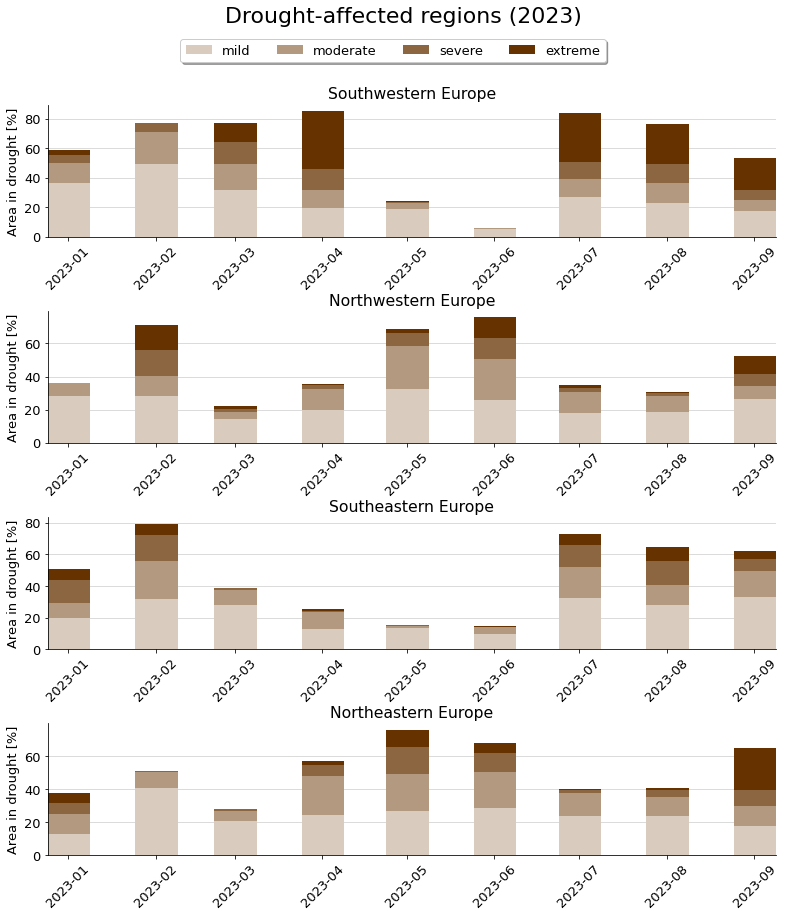

In [22]:
plot_annual_cycle_aid_subregions_bars(aid_spi1, selyear=2023)
plot_annual_cycle_aid_subregions_bars(aid_spei1, selyear=2023)

In [23]:
def plot_annual_cycle_aid_subregions(aid_index, selyear=2023, severity='any'):
    
    fig, (ax1,ax2,ax3,ax4) = plt.subplots(4, 1, sharex=False, figsize=(7.5,12))
    plt.setp([ax1,ax2,ax3,ax4], xticks=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], xticklabels=['J','F','M','A','M','J','J','A','S','O','N','D'])

    fig.tight_layout(pad=3.75)
    fig.subplots_adjust(top=0.875)
    font = {'family' : 'sans-serif',
            'weight' : 'normal',
            'size'   : 13}
    plt.rc('font', **font)

    regions = list(esotc_regions.keys())
    isev    = severity

    iregion = regions[1]
    for iyear in range(1991,2021):
        pidata = aid_index[iregion][isev].sel(time=aid_index[iregion][isev].time.dt.year.isin([iyear])).to_series()
        ax1.plot(pidata.values, color='lightgrey', alpha=1)
    pidata = aid_index[iregion][isev].sel(time=aid_index[iregion][isev].time.dt.year.isin([selyear])).to_series()
    ax1.plot(pidata.values, color=color_list[0], alpha=1, label=selyear, linewidth=2)
    ax1.set_ylabel("Area in drought [%]")
    ax1.margins(x=0)
    ax1.set_title(iregion)

    iregion = regions[2]
    for iyear in range(1991,2021):
        pidata = aid_index[iregion][isev].sel(time=aid_index[iregion][isev].time.dt.year.isin([iyear])).to_series()
        ax2.plot(pidata.values, color='lightgrey', alpha=1)
    pidata = aid_index[iregion][isev].sel(time=aid_index[iregion][isev].time.dt.year.isin([selyear])).to_series()
    ax2.plot(pidata.values, color=color_list[0], alpha=1, label=selyear, linewidth=2)
    ax2.set_ylabel("Area in drought [%]")
    ax2.margins(x=0)
    ax2.set_title(iregion)


    iregion = regions[3]
    for iyear in range(1991,2021):
        pidata = aid_index[iregion][isev].sel(time=aid_index[iregion][isev].time.dt.year.isin([iyear])).to_series()
        ax3.plot(pidata.values, color='lightgrey', alpha=1)
    pidata = aid_index[iregion][isev].sel(time=aid_index[iregion][isev].time.dt.year.isin([selyear])).to_series()
    ax3.plot(pidata.values, color=color_list[0], alpha=1, label=selyear, linewidth=2)
    ax3.set_ylabel("Area in drought [%]")
    ax3.margins(x=0)
    ax3.set_title(iregion)


    iregion = regions[4]
    for iyear in range(1991,2021):
        pidata = aid_index[iregion][isev].sel(time=aid_index[iregion][isev].time.dt.year.isin([iyear])).to_series()
        ax4.plot(pidata.values, color='lightgrey', alpha=1)
    pidata = aid_index[iregion][isev].sel(time=aid_index[iregion][isev].time.dt.year.isin([selyear])).to_series()
    ax4.plot(pidata.values, color=color_list[0], alpha=1, label=selyear, linewidth=2)
    ax4.set_ylabel("Area in drought [%]")
    ax4.margins(x=0)
    ax4.set_title(iregion)

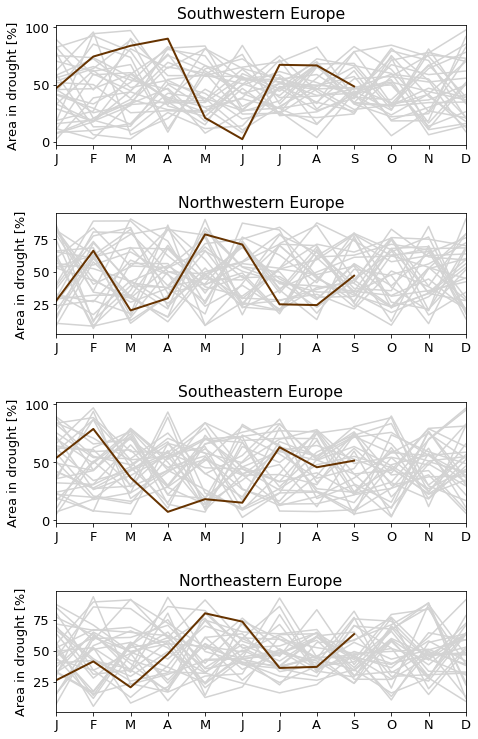

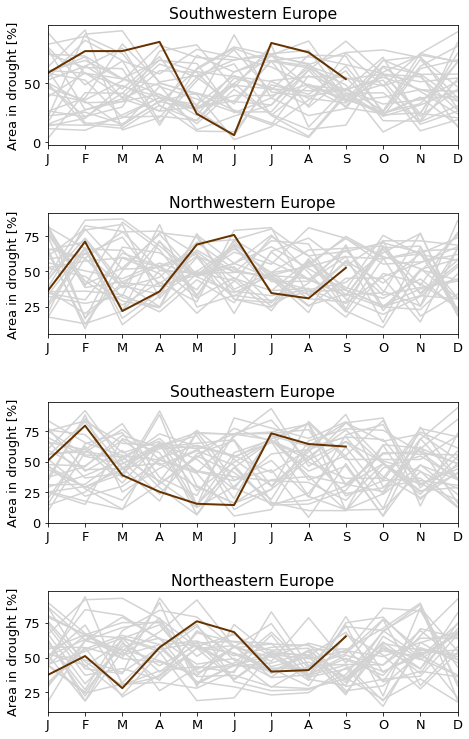

In [24]:
plot_annual_cycle_aid_subregions(aid_spi1, selyear=2023, severity='any')
plot_annual_cycle_aid_subregions(aid_spei1, selyear=2023, severity='any')

In [28]:
def plot_annual_cycle_aid_subregions_modsevextr(aid_index, selyear=2023):
    
    fig, (ax1,ax2,ax3,ax4) = plt.subplots(4, 1, sharex=False, figsize=(7.5,12))
    plt.setp([ax1,ax2,ax3,ax4], xticks=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], xticklabels=['J','F','M','A','M','J','J','A','S','O','N','D'])
    fig.tight_layout(pad=3.75)
    fig.subplots_adjust(top=0.875)
    font = {'family' : 'sans-serif',
            'weight' : 'normal',
            'size'   : 13}
    plt.rc('font', **font)

    regions = list(esotc_regions.keys())

    iregion = regions[1]
    for iyear in range(1991,2021):
        pidata1 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([iyear])).to_series()
        pidata2 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([iyear])).to_series()
        pidata3 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([iyear])).to_series()
        pidata = pidata1 + pidata2 + pidata3
        ax1.plot(pidata.values, color='lightgrey', alpha=1)
    pidata1 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([selyear])).to_series()
    pidata2 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([selyear])).to_series()
    pidata3 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([selyear])).to_series()
    pidata = pidata1 + pidata2 + pidata3
    ax1.plot(pidata.values, color=color_list[0], alpha=1, label='2023', linewidth=2)
    ax1.set_ylabel("Area in drought [%]")
    ax1.margins(x=0)
    ax1.set_title(iregion)

    iregion = regions[2]
    for iyear in range(1991,2021):
        pidata1 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([iyear])).to_series()
        pidata2 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([iyear])).to_series()
        pidata3 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([iyear])).to_series()
        pidata = pidata1 + pidata2 + pidata3
        ax2.plot(pidata.values, color='lightgrey', alpha=1)
    pidata1 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([selyear])).to_series()
    pidata2 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([selyear])).to_series()
    pidata3 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([selyear])).to_series()
    pidata = pidata1 + pidata2 + pidata3
    ax2.plot(pidata.values, color=color_list[0], alpha=1, label='2023', linewidth=2)
    ax2.set_ylabel("Area in drought [%]")
    ax2.margins(x=0)
    ax2.set_title(iregion)


    iregion = regions[3]
    for iyear in range(1991,2021):
        pidata1 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([iyear])).to_series()
        pidata2 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([iyear])).to_series()
        pidata3 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([iyear])).to_series()
        pidata = pidata1 + pidata2 + pidata3
        ax3.plot(pidata.values, color='lightgrey', alpha=1)
    pidata1 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([selyear])).to_series()
    pidata2 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([selyear])).to_series()
    pidata3 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([selyear])).to_series()
    pidata = pidata1 + pidata2 + pidata3
    ax3.plot(pidata.values, color=color_list[0], alpha=1, label='2023', linewidth=2)
    ax3.set_ylabel("Area in drought [%]")
    ax3.margins(x=0)
    ax3.set_title(iregion)


    iregion = regions[4]
    for iyear in range(1991,2021):
        pidata1 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([iyear])).to_series()
        pidata2 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([iyear])).to_series()
        pidata3 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([iyear])).to_series()
        pidata = pidata1 + pidata2 + pidata3
        ax4.plot(pidata.values, color='lightgrey', alpha=1)
    pidata1 = aid_index[iregion]['moderate'].sel(time=aid_index[iregion]['moderate'].time.dt.year.isin([selyear])).to_series()
    pidata2 = aid_index[iregion]['severe'].sel(time=aid_index[iregion]['severe'].time.dt.year.isin([selyear])).to_series()
    pidata3 = aid_index[iregion]['extreme'].sel(time=aid_index[iregion]['extreme'].time.dt.year.isin([selyear])).to_series()
    pidata = pidata1 + pidata2 + pidata3
    ax4.plot(pidata.values, color=color_list[0], alpha=1, label=selyear, linewidth=2)
    ax4.set_ylabel("Area in drought [%]")
    ax4.margins(x=0)
    ax4.set_title(iregion)
    #ax1.spines['top'].set_visible(False)
    #ax1.spines['right'].set_visible(False)
    #ax1.set_xticklabels(range(12), ['J','F','M','A','M','J','J','A','S','O','N','D'])
    #ax1.set_axisbelow(True)
    #ax1.yaxis.grid(color='lightgray', linestyle='solid') #dashed
    #for tick in ax1.get_xticklabels():
    #    tick.set_rotation(45)

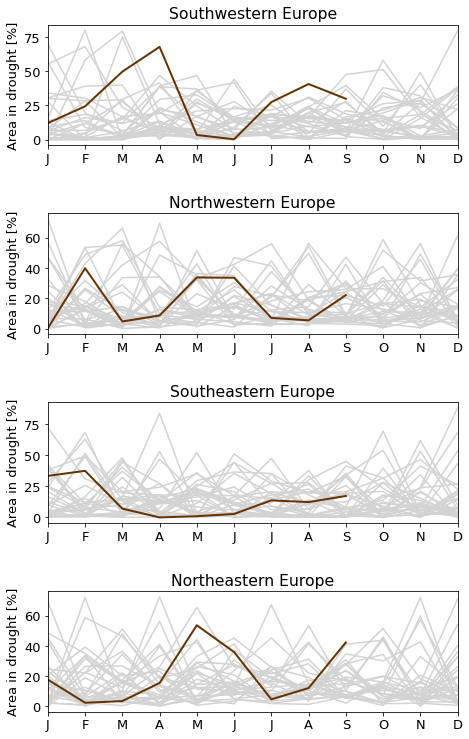

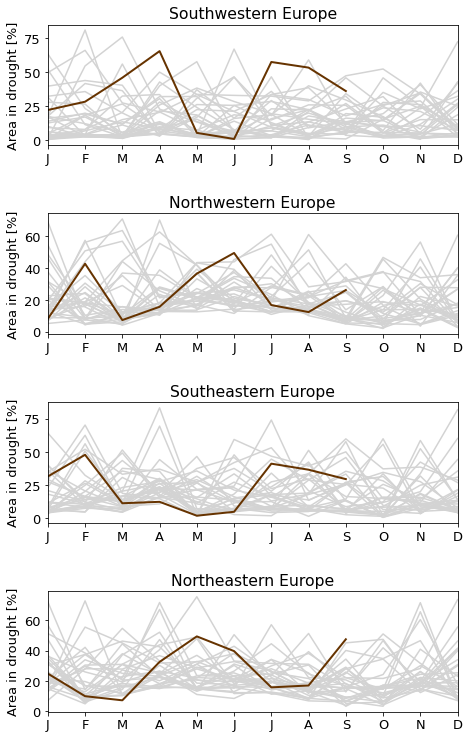

In [29]:
plot_annual_cycle_aid_subregions_modsevextr(aid_spi1, selyear=2023)
plot_annual_cycle_aid_subregions_modsevextr(aid_spei1, selyear=2023)

<xarray.DataArray (time: 1005)>
array([83.72430596, 64.99851144, 42.77617735, ..., 31.95120267,
       32.50345392, 57.18062553])
Coordinates:
  * time     (time) datetime64[ns] 1940-01-01T06:00:00 ... 2023-09-01T06:00:00


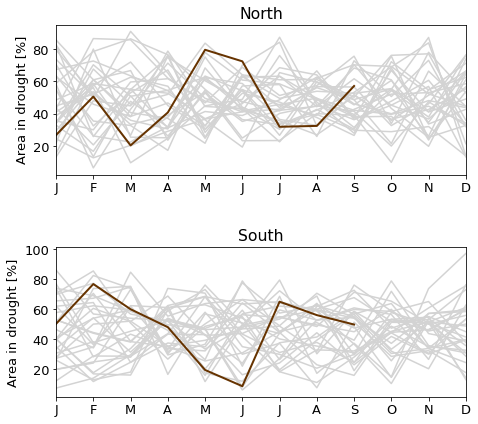

In [32]:
def plot_annual_cycle_aid_north_south(aid_index, selyear=2023, severity='any'):

    fig, (ax1,ax2) = plt.subplots(2, 1, sharex=False, figsize=(7.5,7))
    plt.setp([ax1,ax2], xticks=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], xticklabels=['J','F','M','A','M','J','J','A','S','O','N','D'])

    fig.tight_layout(pad=3.75)
    fig.subplots_adjust(top=0.875)
    font = {'family' : 'sans-serif',
            'weight' : 'normal',
            'size'   : 13}
    plt.rc('font', **font)

    regions = list(esotc_regions.keys())
    isev    = severity

    for iyear in range(1991,2021):
        #pidata = aid_index[regions[2]][isev].sel(time=aid_index[regions[2]][isev].time.dt.year.isin([iyear])).to_series() + aid_index[regions[4]][isev].sel(time=aid_index[regions[4]][isev].time.dt.year.isin([iyear])).to_series()
        pidata = aid_index['Northern Europe'][isev].sel(time=aid_index['Northern Europe'][isev].time.dt.year.isin([iyear])).to_series() 
        ax1.plot(pidata.values, color='lightgrey', alpha=1)
    #pidata = aid_index[regions[2]][isev].sel(time=aid_index[regions[2]][isev].time.dt.year.isin([selyear])).to_series() + aid_index[regions[4]][isev].sel(time=aid_index[regions[4]][isev].time.dt.year.isin([selyear])).to_series()
    pidata = aid_index['Northern Europe'][isev].sel(time=aid_index['Northern Europe'][isev].time.dt.year.isin([selyear])).to_series()
    ax1.plot(pidata.values, color=color_list[0], alpha=1, label=selyear, linewidth=2)
    ax1.set_ylabel("Area in drought [%]")
    ax1.margins(x=0)
    ax1.set_title("North")

    for iyear in range(1991,2021):
        #pidata = aid_index[regions[1]][isev].sel(time=aid_index[regions[1]][isev].time.dt.year.isin([iyear])).to_series() + aid_index[regions[3]][isev].sel(time=aid_index[regions[3]][isev].time.dt.year.isin([iyear])).to_series()
        pidata = aid_index['Southern Europe'][isev].sel(time=aid_index['Southern Europe'][isev].time.dt.year.isin([iyear])).to_series() 
        ax2.plot(pidata.values, color='lightgrey', alpha=1)
    pidata = aid_index['Southern Europe'][isev].sel(time=aid_index['Southern Europe'][isev].time.dt.year.isin([selyear])).to_series()
    ax2.plot(pidata.values, color=color_list[0], alpha=1, label=selyear, linewidth=2)
    ax2.set_ylabel("Area in drought [%]")
    ax2.margins(x=0)
    ax2.set_title("South")
    
plot_annual_cycle_aid_north_south(aid_spi1, selyear=2023, severity='any')
#print(aid_spi1['Northern Europe']['any'])

# Adding fire hotspots!

In [33]:
#fire_days      = xr.open_dataset(os.path.join("data_retrieval/esotc_2023_fires_frp_monsum_days.nc"))["var99"]
fires_jan = xr.open_dataset(os.path.join("/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_01_T_esotc_europe.nc"))["ACTIVE_FIRE"].sel(lat=slice(34, 72),lon=slice(-25, 40))
fires_feb = xr.open_dataset(os.path.join("/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_02_T_esotc_europe.nc"))["ACTIVE_FIRE"].sel(lat=slice(34, 72),lon=slice(-25, 40))
fires_mar = xr.open_dataset(os.path.join("/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_03_T_esotc_europe.nc"))["ACTIVE_FIRE"].sel(lat=slice(34, 72),lon=slice(-25, 40))
fires_apr = xr.open_dataset(os.path.join("/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_04_T_esotc_europe.nc"))["ACTIVE_FIRE"].sel(lat=slice(34, 72),lon=slice(-25, 40))
fires_may = xr.open_dataset(os.path.join("/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_05_T_esotc_europe.nc"))["ACTIVE_FIRE"].sel(lat=slice(34, 72),lon=slice(-25, 40))
fires_jun = xr.open_dataset(os.path.join("/ec/vol/centaur/pajm/ACTIVEint_FIRE_MAP_1KM_2023_06_T.nc"))["ACTIVE_FIRE"].sel(lat=slice(34, 72),lon=slice(-25, 40))
fires_jul = xr.open_dataset(os.path.join("/ec/vol/centaur/pajm/ACTIVEint_FIRE_MAP_1KM_2023_07_T.nc"))["ACTIVE_FIRE"].sel(lat=slice(34, 72),lon=slice(-25, 40))
fires_aug = xr.open_dataset(os.path.join("/ec/vol/centaur/pajm/ACTIVEint_FIRE_MAP_1KM_2023_08_T.nc"))["ACTIVE_FIRE"].sel(lat=slice(34, 72),lon=slice(-25, 40))
fires_sep = xr.open_dataset(os.path.join("/ec/vol/centaur/pajm/ACTIVEint_FIRE_MAP_1KM_2023_09_T.nc"))["ACTIVE_FIRE"].sel(lat=slice(34, 72),lon=slice(-25, 40))
#print(fires_jun)
#print(fires_jul)
#print(fires_aug)
#print(fires_sep)
#fires = xr.concat([fires_jun, fires_jul, fires_aug, fires_sep], 'time')
#print(fires)

In [34]:
fires_jan
#np.asarray(fire_days.sel(time="2023-07-16").values[:])[0,:,:]

<xarray.DataArray 'ACTIVE_FIRE' (time: 1, lat: 0, lon: 1)>
[0 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 2023-01-16
  * lon      (lon) float64 0.0
  * lat      (lat) float64 
Attributes:
    cell_methods:  time: sum

<xarray.DataArray 'time' ()>
array('2023-09-01T06:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 2023-09-01T06:00:00
(1, 3800, 6500)


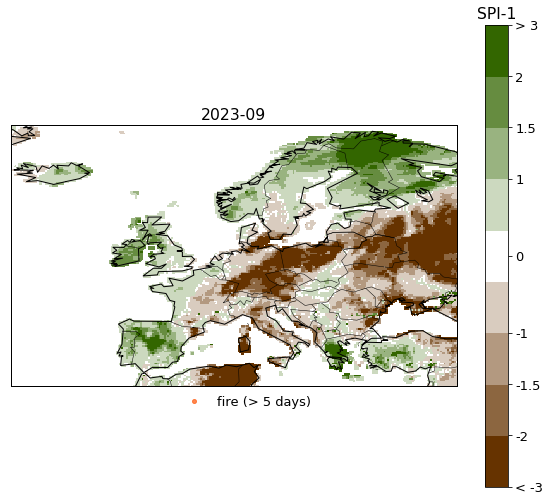

<xarray.DataArray 'time' ()>
array('2023-08-01T06:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 2023-08-01T06:00:00
(1, 3800, 6500)


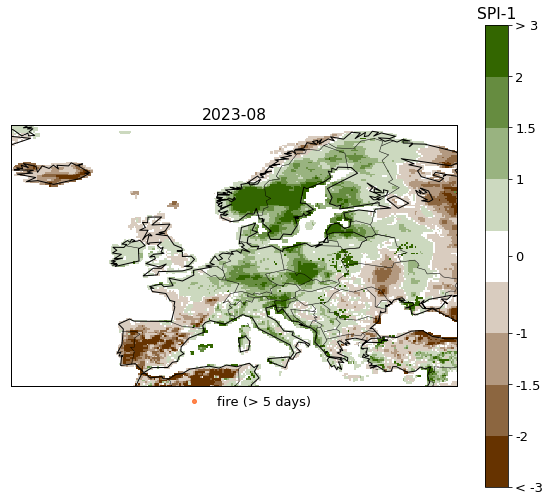

<xarray.DataArray 'time' ()>
array('2023-07-01T06:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 2023-07-01T06:00:00
(1, 3800, 6500)


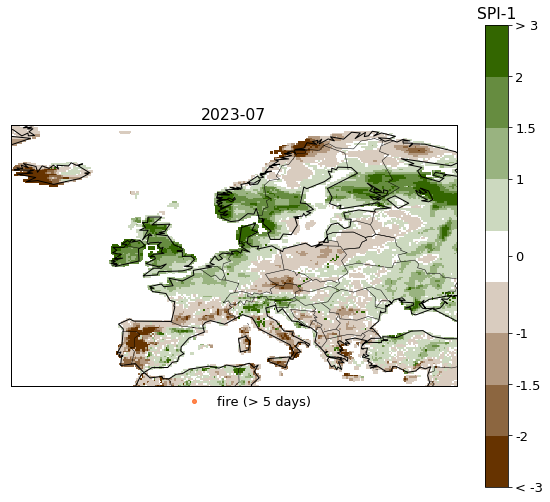

<xarray.DataArray 'time' ()>
array('2023-06-01T06:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 2023-06-01T06:00:00
(1, 3800, 6500)


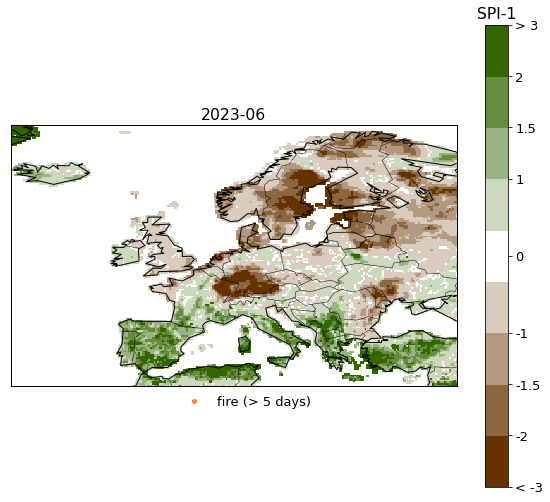

In [35]:
import bisect 
from matplotlib.lines import Line2D

for itime in [1,2,3,4]:

    print(spi1.sel(time=spi1.time[-itime]).time)
    stime = spi1.time.dt.strftime('%Y-%m-15').values[:][-itime]
    ptime = spi1.time.dt.strftime('%Y-%m').values[:][-itime]
    
    if itime==1:
        fires = fires_sep
    if itime==2:
        fires = fires_aug
    if itime==3:
        fires = fires_jul
    if itime==4:
        fires = fires_jun
    print(fires.values[:].shape)
    
    map_2d =  np.asarray(spi1.sel(time=spi1.time[-itime]).values[:])
    plot_type = "pcolormesh"
    xlab="longitude ["+chr(176)+"]"
    ylab="latitude ["+chr(176)+"]" 
    xlim=[-25, 40]
    ylim=[34, 72]
    zlim=[-3,3]
    xlab=""
    ylab=""
    main_title=""
    main_title=f"{ptime}"
    legend_title=f"SPI-1"
    colorscheme=cmap_spi
    levels=clevels
    legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3]
    legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"]

    fig = plt.figure(figsize=(10,10), frameon=False)
    # adjust limits for plotting
    map_2d[map_2d <= zlim[0]] = zlim[0]
    map_2d[map_2d >= zlim[1]] = zlim[1]

    # basemap
    m = Basemap(projection='cyl', llcrnrlon=-180, \
        urcrnrlon=180.,llcrnrlat=grid_lat.min(),urcrnrlat=grid_lat.max(), \
        resolution='c')

    flats = np.asarray(fires.lat)
    flons = np.asarray(fires.lon)
    fgrid_lon, fgrid_lat = np.meshgrid(flons, flats)
    fx, fy = m(fgrid_lon, fgrid_lat)

    m.drawcoastlines()
    #m.fillcontinents()
    m.drawmapboundary()
    m.drawcountries()
    #m.shadedrelief()
    #m.drawrivers()
    #m.drawlsmask()

    if plot_type == "contourf":
        ax1 = m.contourf(grid_lon, grid_lat, map_2d, cmap=colorscheme, levels=levels)
    if plot_type == "pcolormesh":
        ax1 = m.pcolormesh(grid_lon, grid_lat, map_2d, shading='auto', cmap=colorscheme, norm=levels)

    # adding fire hotspots...
    fire_levels = [0, 1, 5, 50]
    plot_type  = 'pcolormesh'
    cmap_fires, flevels = create_diverging_colorscheme("goldorange", start_color = (1, 1, 1), mid_color = (255/255,215/255,1/255), end_color = (255/255, 95/255, 21/255), 
                                                     levels = fire_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
    #cmap_fires, flevels = create_diverging_colorscheme("reds", start_color = (1, 1, 1), mid_color = (255/255,153/255,153/255), end_color = (153/255, 0, 0), 
    #                                                 levels = fire_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
    fcolor_list = [colors.rgb2hex(cmap_fires(i)) for i in range(cmap_fires.N)]
    #m.pcolormesh(fx, fy, np.asarray(fire_days.sel(time="2023-07-16").values[:])[0,:,:])
    #m.contourf(fx, fy, np.asarray(fire_days.sel(time="2023-07-16").values[:])[0,:,:], alpha=.5, antialiased=True)
    #fires = np.asarray(fire_days.sel(time=stime).values[:])[0,:,:]
    #m.scatter(fx, fy, fires, alpha=.5, c='crimson')
    #for ix in range(len(flons)):
    #    for iy in range(len(flats)):
    #        if fires[0,iy,ix] >= 5:
    #            isize = (fires[iy,ix]/5)**2
    #            ibin  = bisect.bisect_right(fire_levels, fires[0,iy,ix])
    #            icols = fcolor_list[ibin-1]
    #            m.scatter(fx[iy,ix], fy[iy,ix], alpha=0.5, c=icols, s=isize)

    plt.xlim(xlim)
    plt.xlabel(xlab)
    plt.ylim(ylim)
    plt.ylabel(ylab)
    plt.title(main_title)
    #plt.text(.01, .01, main_title,
    #         horizontalalignment='left',
    #         verticalalignment='bottom',
    #         size = 15,
    #         transform = plt.gca().transAxes)#

    cbar = plt.colorbar(ax1, orientation='vertical', shrink=0.85)
    cbar.ax.set_title(legend_title)
    if legend_ticks is not None:
        cbar.set_ticks(legend_ticks)
    if legend_ticklabels is not None:
        cbar.set_ticklabels(legend_ticklabels)

    #legend_elements = [Line2D([0], [0], marker='o', color=fcolor_list[1], label='fire (1-5 days)', markerfacecolor=fcolor_list[1], markersize=(7.5/5)**2, alpha=0.75, linestyle=''),
    #                   Line2D([0], [0], marker='o', color=fcolor_list[2], label='fire (>5 days)', markerfacecolor=fcolor_list[2], markersize=(12.5/5)**2, alpha=0.75, linestyle='')]
    legend_elements = [Line2D([0], [0], marker='o', color=fcolor_list[2], label='fire (> 5 days)', markerfacecolor=fcolor_list[2], markersize=(10/5)**2, alpha=0.75, linestyle='')]
    plt.legend(handles=legend_elements, bbox_to_anchor=(0.7, 0.01), ncol=2, frameon=False)
    plt.show()

<ipython-input-36-454c5e6b8356>:2: UserWarning: This figure was using constrained_layout==True, but that is incompatible with subplots_adjust and or tight_layout: setting constrained_layout==False. 
  fig.tight_layout()


2191
1818
2768
4333
5584
3959
6840
2665


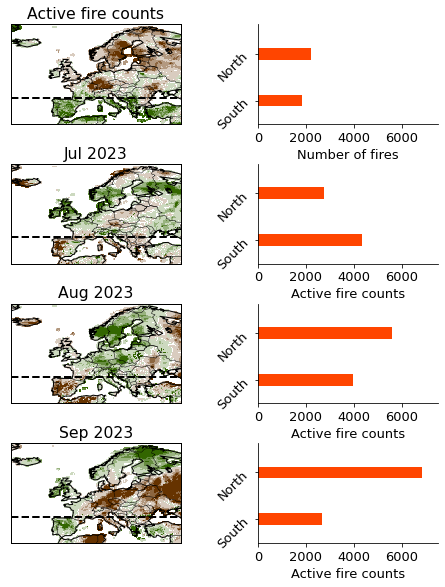

In [36]:
fig, axs = plt.subplots(4, 2, figsize=(7.5,12), constrained_layout = True)
fig.tight_layout()

plt.subplots_adjust(left=0.1,
                    bottom=0.3, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)
#plt.show()

plot_type = "pcolormesh"
xlab="longitude ["+chr(176)+"]"
ylab="latitude ["+chr(176)+"]" 
xlim=[-25, 40]
ylim=[34, 72]
zlim=[-3,3]
xlab=""
ylab=""
main_title=""
main_title=f"{ptime}"
legend_title=f"SPI-1"
colorscheme=cmap_spi
levels=clevels
legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3]
legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"]

# June
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-4]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[0,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - fire activity
nfires_north = fires_jun.sel(lat=slice(44, 72),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
nfires_south = fires_jun.sel(lat=slice(34, 44),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
print(nfires_north.values[:][0])
print(nfires_south.values[:][0])
axs[0,1].barh([0,1], width = [nfires_south.values[:][0], nfires_north.values[:][0]], height = [0.25, 0.25], color=['orangered'])
axs[0,1].set_xlabel("Number of fires")
axs[0,1].set_ylim([-0.5,1.625])
axs[0,1].set_xlim([0,7500])
axs[0,0].set_title("Active fire counts")
axs[0,1].spines['top'].set_visible(False)
axs[0,1].spines['right'].set_visible(False)
axs[0,1].spines['bottom'].set_visible(True)
axs[0,1].spines['left'].set_visible(True)
#axs[0,1].set(yticklabels=[])  
axs[0,1].set(ylabel=None)  # remove the y-axis label
#axs[0,1].tick_params(left=False)
axs[0,1].set_yticks([0,1])
axs[0,1].set_yticklabels(["South","North"])
axs[0,1].set(ylabel=None)  # remove the y-axis label
axs[0,1].tick_params(axis='y', labelrotation = 45)
del(nfires_north, nfires_south)



# July
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-3]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[1,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - fire activity
nfires_north = fires_jul.sel(lat=slice(44, 72),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
nfires_south = fires_jul.sel(lat=slice(34, 44),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
print(nfires_north.values[:][0])
print(nfires_south.values[:][0])
axs[1,1].barh([0,1], width = [nfires_south.values[:][0], nfires_north.values[:][0]], height = [0.25, 0.25], color=['orangered'])
axs[1,1].set_xlabel("Active fire counts")
axs[1,1].set_ylim([-0.5,1.625])
axs[1,1].set_xlim([0,7500])
axs[1,0].set_title("Jul 2023")
axs[1,1].spines['top'].set_visible(False)
axs[1,1].spines['right'].set_visible(False)
axs[1,1].spines['bottom'].set_visible(True)
axs[1,1].spines['left'].set_visible(True)
#axs[1,1].set(yticklabels=[])  
axs[1,1].set(ylabel=None)  # remove the y-axis label
#axs[1,1].tick_params(left=False)
axs[1,1].set_yticks([0,1])
axs[1,1].set_yticklabels(["South","North"])
axs[1,1].set(ylabel=None)  # remove the y-axis label
axs[1,1].tick_params(axis='y', labelrotation = 45)
del(nfires_north, nfires_south)




# August
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-2]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[2,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - fire activity
nfires_north = fires_aug.sel(lat=slice(44, 72),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
nfires_south = fires_aug.sel(lat=slice(34, 44),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
print(nfires_north.values[:][0])
print(nfires_south.values[:][0])
axs[2,1].barh([0,1], width = [nfires_south.values[:][0], nfires_north.values[:][0]], height = [0.25, 0.25], color=['orangered'])
axs[2,1].set_xlabel("Active fire counts")
axs[2,1].set_ylim([-0.5,1.625])
axs[2,1].set_xlim([0,7500])
axs[2,0].set_title("Aug 2023")
axs[2,1].spines['top'].set_visible(False)
axs[2,1].spines['right'].set_visible(False)
axs[2,1].spines['bottom'].set_visible(True)
axs[2,1].spines['left'].set_visible(True)
#axs[2,1].set(yticklabels=[])  
axs[2,1].set(ylabel=None)  # remove the y-axis label
#axs[2,1].tick_params(left=False)
axs[2,1].set_yticks([0,1])
axs[2,1].set_yticklabels(["South","North"])
axs[2,1].set(ylabel=None)  # remove the y-axis label
axs[2,1].tick_params(axis='y', labelrotation = 45)
del(nfires_north, nfires_south)


# September
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-1]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[3,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - fire activity
nfires_north = fires_sep.sel(lat=slice(44, 72),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
nfires_south = fires_sep.sel(lat=slice(34, 44),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
print(nfires_north.values[:][0])
print(nfires_south.values[:][0])
axs[3,1].barh([0,1], width = [nfires_south.values[:][0], nfires_north.values[:][0]], height = [0.25, 0.25], color=['orangered'])
axs[3,1].set_xlabel("Active fire counts")
axs[3,1].set_ylim([-0.5,1.625])
axs[3,1].set_xlim([0,7500])
axs[3,0].set_title("Sep 2023")
axs[3,1].spines['top'].set_visible(False)
axs[3,1].spines['right'].set_visible(False)
axs[3,1].spines['bottom'].set_visible(True)
axs[3,1].spines['left'].set_visible(True)
#axs[3,1].set(yticklabels=[])  
axs[3,1].set(ylabel=None)  # remove the y-axis label
#axs[3,1].tick_params(left=False)
axs[3,1].set_yticks([0,1])
axs[3,1].set_yticklabels(["South","North"])
axs[3,1].set(ylabel=None)  # remove the y-axis label
axs[3,1].tick_params(axis='y', labelrotation = 45)
del(nfires_north, nfires_south)


In [45]:
# - fire activity
#fires_jun.sel(lat=slice(44, 72),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
subregions_nfires_jan = {}
subregions_nfires_feb = {}
subregions_nfires_mar = {}
subregions_nfires_apr = {}
subregions_nfires_may = {}
subregions_nfires_jun = {}
subregions_nfires_jul = {}
subregions_nfires_aug = {}
subregions_nfires_sep = {}

for iregion in esotc_regions.keys():
    
    print(iregion)
    
    if iregion == "Europe":
        iregion_str = iregion.lower()
    if iregion == "Southern Europe":
        continue
    if iregion == "Northern Europe":
        continue
    if iregion == "Northwestern Europe":
        iregion_str = "nweurope"
    if iregion == "Northeastern Europe":
        iregion_str = "neeurope"
    if iregion == "Southwestern Europe":
        iregion_str = "sweurope"
    if iregion == "Southeastern Europe":
        iregion_str = "seeurope"
    
    #mask_lon = (fires_jun.lon >= esotc_regions[iregion]['extent'][0]) & (fires_jun.lon <= esotc_regions[iregion]['extent'][1])
    #mask_lat = (fires_jun.lat >= esotc_regions[iregion]['extent'][2]) & (fires_jun.lat <= esotc_regions[iregion]['extent'][3])

    # Jan
    subregions_nfires_jan[iregion] = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_01_T_esotc_{iregion_str}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]

    # Feb
    subregions_nfires_feb[iregion] = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_02_T_esotc_{iregion_str}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]

    # Mar
    subregions_nfires_mar[iregion] = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_03_T_esotc_{iregion_str}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]

    # Apr
    subregions_nfires_apr[iregion] = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_04_T_esotc_{iregion_str}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]

    # May
    subregions_nfires_may[iregion] = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_05_T_esotc_{iregion_str}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]

    # June
    #subregions_nfires_jun[iregion] = fires_jun.where(mask_lon & mask_lat, drop=False).sum(dim=["lon", "lat"]).values[:][0]
    subregions_nfires_jun[iregion] = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_06_T_esotc_{iregion_str}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    
    # July
    #subregions_nfires_jul[iregion] = fires_jul.where(mask_lon & mask_lat, drop=False).sum(dim=["lon", "lat"]).values[:][0]
    subregions_nfires_jul[iregion] = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_07_T_esotc_{iregion_str}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    
    # Aug
    #subregions_nfires_aug[iregion] = fires_aug.where(mask_lon & mask_lat, drop=False).sum(dim=["lon", "lat"]).values[:][0]
    subregions_nfires_aug[iregion] = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_08_T_esotc_{iregion_str}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]

    # Sep
    #subregions_nfires_sep[iregion] = fires_sep.where(mask_lon & mask_lat, drop=False).sum(dim=["lon", "lat"]).values[:][0]
    subregions_nfires_sep[iregion] = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_09_T_esotc_{iregion_str}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]


for iregion in ["Northern Europe", "Southern Europe"]:
    
    print(iregion)
    
    if iregion == "Northern Europe":
        iregion_str1 = "nweurope"
        iregion_str2 = "neeurope"
    if iregion == "Southern Europe":
        iregion_str1 = "sweurope"
        iregion_str2 = "seeurope"
        
    # Jan
    tmp1 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_01_T_esotc_{iregion_str1}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    tmp2 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_01_T_esotc_{iregion_str2}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    subregions_nfires_jan[iregion] = tmp1 + tmp2
   
    # Feb
    tmp1 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_02_T_esotc_{iregion_str1}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    tmp2 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_02_T_esotc_{iregion_str2}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    subregions_nfires_feb[iregion] = tmp1 + tmp2

    # Mar
    tmp1 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_03_T_esotc_{iregion_str1}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    tmp2 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_03_T_esotc_{iregion_str2}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    subregions_nfires_mar[iregion] = tmp1 + tmp2
    
    # Apr
    tmp1 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_04_T_esotc_{iregion_str1}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    tmp2 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_04_T_esotc_{iregion_str2}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    subregions_nfires_apr[iregion] = tmp1 + tmp2
    
    # May
    tmp1 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_05_T_esotc_{iregion_str1}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    tmp2 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_05_T_esotc_{iregion_str2}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    subregions_nfires_may[iregion] = tmp1 + tmp2

    # Jun
    tmp1 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_06_T_esotc_{iregion_str1}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    tmp2 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_06_T_esotc_{iregion_str2}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    subregions_nfires_jun[iregion] = tmp1 + tmp2

    # Jul
    tmp1 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_07_T_esotc_{iregion_str1}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    tmp2 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_07_T_esotc_{iregion_str2}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    subregions_nfires_jul[iregion] = tmp1 + tmp2

    # Aug
    tmp1 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_08_T_esotc_{iregion_str1}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    tmp2 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_08_T_esotc_{iregion_str2}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    subregions_nfires_aug[iregion] = tmp1 + tmp2

    # Sep
    tmp1 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_09_T_esotc_{iregion_str1}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    tmp2 = xr.open_dataset(os.path.join(f"/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/ACTIVEint_FIRE_MAP_1KM_2023_09_T_esotc_{iregion_str2}.nc"))["ACTIVE_FIRE"].values[:][0][0][0]
    subregions_nfires_sep[iregion] = tmp1 + tmp2

Europe
Southwestern Europe
Northwestern Europe
Southeastern Europe
Northeastern Europe
Southern Europe
Northern Europe
Northern Europe
Southern Europe


<ipython-input-38-52bfa49268f8>:5: UserWarning: This figure was using constrained_layout==True, but that is incompatible with subplots_adjust and or tight_layout: setting constrained_layout==False. 
  fig.tight_layout()


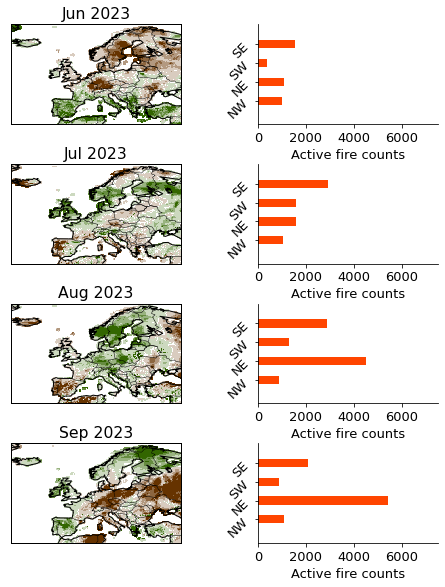

In [38]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.axes_divider import make_axes_area_auto_adjustable

fig, axs = plt.subplots(4, 2, figsize=(7.5,12), constrained_layout = True)
fig.tight_layout()
plt.subplots_adjust(left=0.1,
                    bottom=0.3, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)
#plt.show()

plot_type = "pcolormesh"
xlab="longitude ["+chr(176)+"]"
ylab="latitude ["+chr(176)+"]"
xlim=[-25, 40]
ylim=[34, 72]
zlim=[-3,3]
xlab=""
ylab=""
main_title=""
main_title=f"{ptime}"
legend_title=f"SPI-1"
colorscheme=cmap_spi
levels=clevels
legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3]
legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"]

# June
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-4]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[0,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - fire activity
axs[0,1].barh([0,0.4,0.8,1.2], 
              width = [subregions_nfires_jun['Northwestern Europe'], 
                       subregions_nfires_jun['Northeastern Europe'], 
                       subregions_nfires_jun['Southwestern Europe'], 
                       subregions_nfires_jun['Southeastern Europe']], 
              height = [0.175, 0.175, 0.175, 0.175], 
              color=['orangered'])
axs[0,1].set_xlabel("Active fire counts")
axs[0,1].set_ylim([-0.5,1.625])
axs[0,1].set_xlim([0,7500])
axs[0,0].set_title("Jun 2023")
axs[0,1].spines['top'].set_visible(False)
axs[0,1].spines['right'].set_visible(False)
axs[0,1].spines['bottom'].set_visible(True)
axs[0,1].spines['left'].set_visible(True)
axs[0,1].set_yticks([0,0.4,0.8,1.2])
axs[0,1].set_yticklabels(["NW","NE","SW","SE"])
axs[0,1].set(ylabel=None)  # remove the y-axis label
axs[0,1].tick_params(axis='y', labelrotation = 45)


# July
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-3]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[1,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - fire activity
axs[1,1].barh([0,0.4,0.8,1.2], 
              width = [subregions_nfires_jul['Northwestern Europe'], 
                       subregions_nfires_jul['Northeastern Europe'], 
                       subregions_nfires_jul['Southwestern Europe'], 
                       subregions_nfires_jul['Southeastern Europe']], 
              height = [0.175, 0.175, 0.175, 0.175], 
              color=['orangered'])
axs[1,1].set_xlabel("Active fire counts")
axs[1,1].set_ylim([-0.5,1.625])
axs[1,1].set_xlim([0,7500])
axs[1,0].set_title("Jul 2023")
axs[1,1].spines['top'].set_visible(False)
axs[1,1].spines['right'].set_visible(False)
axs[1,1].spines['bottom'].set_visible(True)
axs[1,1].spines['left'].set_visible(True)
axs[1,1].set_yticks([0,0.4,0.8,1.2])
axs[1,1].set_yticklabels(["NW","NE","SW","SE"])
axs[1,1].set(ylabel=None)  # remove the y-axis label
axs[1,1].tick_params(axis='y', labelrotation = 45)




# August
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-2]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[2,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - fire activity
axs[2,1].barh([0,0.4,0.8,1.2], 
              width = [subregions_nfires_aug['Northwestern Europe'], 
                       subregions_nfires_aug['Northeastern Europe'], 
                       subregions_nfires_aug['Southwestern Europe'], 
                       subregions_nfires_aug['Southeastern Europe']], 
              height = [0.175, 0.175, 0.175, 0.175], 
              color=['orangered'])
axs[2,1].set_xlabel("Active fire counts")
axs[2,1].set_ylim([-0.5,1.625])
axs[2,1].set_xlim([0,7500])
axs[2,0].set_title("Aug 2023")
axs[2,1].spines['top'].set_visible(False)
axs[2,1].spines['right'].set_visible(False)
axs[2,1].spines['bottom'].set_visible(True)
axs[2,1].spines['left'].set_visible(True)
axs[2,1].set_yticks([0,0.4,0.8,1.2])
axs[2,1].set_yticklabels(["NW","NE","SW","SE"])
axs[2,1].set(ylabel=None)  # remove the y-axis label
axs[2,1].tick_params(axis='y', labelrotation = 45)


# September
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-1]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[3,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - fire activity
axs[3,1].barh([0,0.4,0.8,1.2], 
              width = [subregions_nfires_sep['Northwestern Europe'], 
                       subregions_nfires_sep['Northeastern Europe'], 
                       subregions_nfires_sep['Southwestern Europe'], 
                       subregions_nfires_sep['Southeastern Europe']], 
              height = [0.175, 0.175, 0.175, 0.175], 
              color=['orangered'])
axs[3,1].set_xlabel("Active fire counts")
axs[3,1].set_ylim([-0.5,1.625])
axs[3,1].set_xlim([0,7500])
axs[3,0].set_title("Sep 2023")
axs[3,1].spines['top'].set_visible(False)
axs[3,1].spines['right'].set_visible(False)
axs[3,1].spines['bottom'].set_visible(True)
axs[3,1].spines['left'].set_visible(True)
axs[3,1].set_yticks([0,0.4,0.8,1.2])
axs[3,1].set_yticklabels(["NW","NE","SW","SE"])
axs[3,1].set(ylabel=None)  # remove the y-axis label
axs[3,1].tick_params(axis='y', labelrotation = 45)

In [49]:
subregions_nfires_north = [subregions_nfires_jan['Northern Europe'], subregions_nfires_feb['Northern Europe'], subregions_nfires_mar['Northern Europe'],
                          subregions_nfires_apr['Northern Europe'], subregions_nfires_may['Northern Europe'], subregions_nfires_jun['Northern Europe'], 
                          subregions_nfires_jul['Northern Europe'], subregions_nfires_aug['Northern Europe'], subregions_nfires_sep['Northern Europe']]
print(subregions_nfires_north)
subregions_nfires_south = [subregions_nfires_jan['Southern Europe'], subregions_nfires_feb['Southern Europe'], subregions_nfires_mar['Southern Europe'],
                          subregions_nfires_apr['Southern Europe'], subregions_nfires_may['Southern Europe'], subregions_nfires_jun['Southern Europe'], 
                          subregions_nfires_jul['Southern Europe'], subregions_nfires_aug['Southern Europe'], subregions_nfires_sep['Southern Europe']]
print(subregions_nfires_south)
subregions_nfires = {'Northern Europe': subregions_nfires_north, 'Southern Europe': subregions_nfires_south}
print(subregions_nfires)

195.0
382.0
1806.0
5757.0
2271.0
2107.0
2607.0
5350.0
6508.0
[195.0, 382.0, 1806.0, 5757.0, 2271.0, 2107.0, 2607.0, 5350.0, 6508.0]
[749.0, 1777.0, 1519.0, 680.0, 851.0, 1902.0, 4494.0, 4193.0, 2997.0]
{'Northern Europe': [195.0, 382.0, 1806.0, 5757.0, 2271.0, 2107.0, 2607.0, 5350.0, 6508.0], 'Southern Europe': [749.0, 1777.0, 1519.0, 680.0, 851.0, 1902.0, 4494.0, 4193.0, 2997.0]}


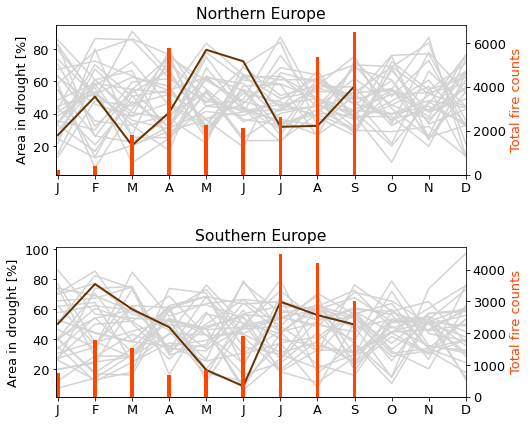

In [54]:
def plot_annual_cycles_north_south(aid_index, fire_index, selyear=2023, severity='any'):

    fig, (ax1,ax2) = plt.subplots(2, 1, sharex=False, figsize=(7.5,7))
    plt.setp([ax1,ax2], xticks=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], xticklabels=['J','F','M','A','M','J','J','A','S','O','N','D'])

    fig.tight_layout(pad=3.75)
    fig.subplots_adjust(top=0.875)
    font = {'family' : 'sans-serif',
            'weight' : 'normal',
            'size'   : 13}
    plt.rc('font', **font)

    regions = list(esotc_regions.keys())
    isev    = severity

    for iyear in range(1991,2021):
        pidata = aid_index['Northern Europe'][isev].sel(time=aid_index['Northern Europe'][isev].time.dt.year.isin([iyear])).to_series() 
        ax1.plot(pidata.values, color='lightgrey', alpha=1)
    pidata = aid_index['Northern Europe'][isev].sel(time=aid_index['Northern Europe'][isev].time.dt.year.isin([selyear])).to_series()
    ax1.plot(pidata.values, color=color_list[0], alpha=1, label=selyear, linewidth=2)
    ax1.set_ylabel("Area in drought [%]")
    ax1.margins(x=0)
    ax1.set_title("Northern Europe")
    ax11 = ax1.twinx()
    bar1 = ax11.bar([0, 1, 2, 3, 4, 5, 6, 7, 8], fire_index['Northern Europe'], width = 0.1, color='orangered')
    ax11.set_ylabel("Total fire counts", color='orangered')
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['bottom'].set_visible(True)
    ax1.spines['left'].set_visible(True)
    
    for iyear in range(1991,2021):
        pidata = aid_index['Southern Europe'][isev].sel(time=aid_index['Southern Europe'][isev].time.dt.year.isin([iyear])).to_series() 
        ax2.plot(pidata.values, color='lightgrey', alpha=1)
    pidata = aid_index['Southern Europe'][isev].sel(time=aid_index['Southern Europe'][isev].time.dt.year.isin([selyear])).to_series()
    ax2.plot(pidata.values, color=color_list[0], alpha=1, label=selyear, linewidth=2)
    ax2.set_ylabel("Area in drought [%]")
    ax2.margins(x=0)
    ax2.set_title("Southern Europe")
    ax22 = ax2.twinx()
    bar2 = ax22.bar([0, 1, 2, 3, 4, 5, 6, 7, 8], fire_index['Southern Europe'], width = 0.1, color='orangered')
    ax22.set_ylabel("Total fire counts", color='orangered')
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.spines['bottom'].set_visible(True)
    ax2.spines['left'].set_visible(True)
    
plot_annual_cycles_north_south(aid_spi1, subregions_nfires, selyear=2023, severity='any')
#print(aid_spi1['Northern Europe']['any'])

## Add number of hot and dry days

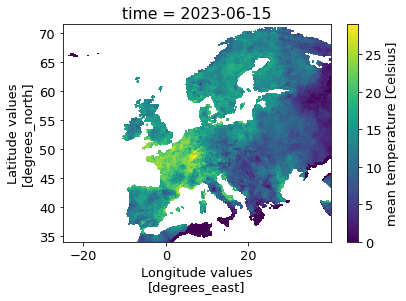

In [55]:
hddays_jun = xr.open_dataset(os.path.join("/home/nejk/code/esotc_drought/data_retrieval/hot_and_dry_days_2023/hot_dry_days_2023month6.nc"))["tg"].sel(latitude=slice(34, 72),longitude=slice(-25, 40))
hddays_jun.plot()
hddays_jul = xr.open_dataset(os.path.join("/home/nejk/code/esotc_drought/data_retrieval/hot_and_dry_days_2023/hot_dry_days_2023month7.nc"))["tg"].sel(latitude=slice(34, 72),longitude=slice(-25, 40))
hddays_aug = xr.open_dataset(os.path.join("/home/nejk/code/esotc_drought/data_retrieval/hot_and_dry_days_2023/hot_dry_days_2023month8.nc"))["tg"].sel(latitude=slice(34, 72),longitude=slice(-25, 40))
hddays_sep = xr.open_dataset(os.path.join("/home/nejk/code/esotc_drought/data_retrieval/hot_and_dry_days_2023/hot_dry_days_2023month9.nc"))["tg"].sel(latitude=slice(34, 72),longitude=slice(-25, 40))

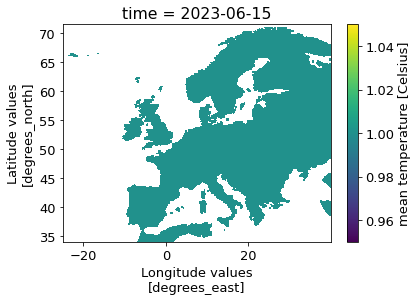

In [56]:
hddlandmask = hddays_jun.where(hddays_jun.isnull(), other = 1, drop=False)#.sum()
hddlandmask.plot()

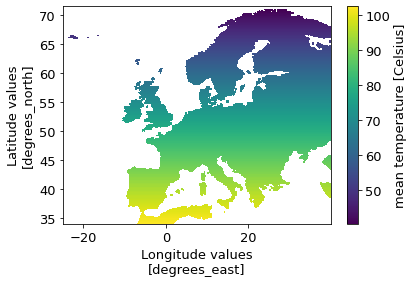

In [57]:
hddarea_2d = calculate_gridarea(hddlandmask.latitude, res=abs(hddlandmask.latitude[1]-hddlandmask.latitude[0]), nlon=len(hddlandmask.longitude))*hddlandmask[0,:,:]
hddarea_2d = xr.DataArray(hddarea_2d, coords={'latitude': hddlandmask.latitude,'longitude': hddlandmask.longitude}, dims=["latitude", "longitude"])
hddarea_2d.plot()

In [58]:
hddarea_3d     = hddarea_2d.expand_dims(dim={"time": hddays_jun.time}, axis=0)
hddlandmask_3d = hddlandmask.reindex_like(hddays_jun, method='nearest')


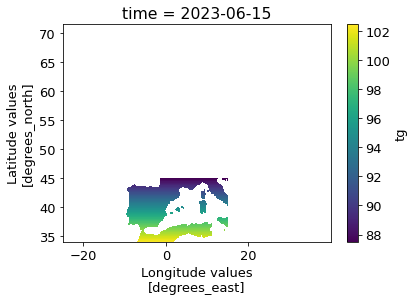

In [59]:
hddsubregions_landmask = {}
hddsubregions_landarea = {}
for iregion in esotc_regions.keys():

    hddsubregions_landmask[iregion] = hddlandmask
    mask_lon = (hddlandmask.longitude >= esotc_regions[iregion]['extent'][0]) & (hddlandmask.longitude <= esotc_regions[iregion]['extent'][1])
    mask_lat = (hddlandmask.latitude >= esotc_regions[iregion]['extent'][2]) & (hddlandmask.latitude <= esotc_regions[iregion]['extent'][3])
    
    hddsubregions_landmask[iregion] = hddsubregions_landmask[iregion].where(mask_lon & mask_lat, drop=False)
    hddsubregions_landarea[iregion] = (hddsubregions_landmask[iregion]*hddarea_2d).where(mask_lon & mask_lat, drop=False)#.sum()

(hddsubregions_landmask['Southwestern Europe']*hddarea_2d).plot()
#print(subregions_landarea['Southwestern Europe'])

In [60]:
# - fire activity
#fires_jun.sel(lat=slice(44, 72),lon=slice(-25, 40)).sum(dim=["lon", "lat"])
subregions_nhdd_jun = {}
subregions_nhdd_jul = {}
subregions_nhdd_aug = {}
subregions_nhdd_sep = {}

for iregion in esotc_regions.keys():
    
    mask_lon = (hddays_jun.longitude >= esotc_regions[iregion]['extent'][0]) & (hddays_jun.longitude <= esotc_regions[iregion]['extent'][1])
    mask_lat = (hddays_jun.latitude >= esotc_regions[iregion]['extent'][2]) & (hddays_jun.latitude <= esotc_regions[iregion]['extent'][3])

    # June
    subregions_nhdd_jun[iregion] = hddays_jun.where(mask_lon & mask_lat, drop=False).sum(dim=["longitude", "latitude"]).values[:][0]
    
    # July
    subregions_nhdd_jul[iregion] = hddays_jul.where(mask_lon & mask_lat, drop=False).sum(dim=["longitude", "latitude"]).values[:][0]
    
    # Aug
    subregions_nhdd_aug[iregion] = hddays_aug.where(mask_lon & mask_lat, drop=False).sum(dim=["longitude", "latitude"]).values[:][0]
    
    # Sep
    subregions_nhdd_sep[iregion] = hddays_sep.where(mask_lon & mask_lat, drop=False).sum(dim=["longitude", "latitude"]).values[:][0]

In [62]:
subregions_nfires_jun['Northern Europe']

2107.0

In [63]:
area_hdd_jun  = {}
area_hdd_jul  = {}
area_hdd_aug  = {}
area_hdd_sep  = {}

for iregion in esotc_regions.keys():
    
    print(iregion)
    area_hdd_jun[iregion]   = {}
    area_hdd_jul[iregion]   = {}
    area_hdd_aug[iregion]   = {}
    area_hdd_sep[iregion]   = {}

    for nndays in [10,15,20,25,30]:

        ndays = f"N{nndays}"
        print(ndays)
        print(hddays_jul.values[:].shape)
        #print(hddsubregions_landmask[iregion].shape)
        
        rhdd   = hddays_jun*(hddsubregions_landmask[iregion].reindex_like(hddays_jun, method="nearest"))
        dmask  = xr.where((rhdd > nndays), 1, np.nan)
        tmp    = (100 * (dmask[0,:,:]*hddarea_3d[0,:,:]).sum(dim=["latitude", "longitude"]) / hddsubregions_landarea[iregion].reindex_like(rhdd, method="nearest").sum(dim=["latitude", "longitude"])).values[0]
        print(tmp)
        area_hdd_jun[iregion][ndays] = tmp
        del(rhdd, dmask, tmp)
        
        rhdd   = hddays_jul*(hddsubregions_landmask[iregion].reindex_like(hddays_jul, method="nearest"))
        dmask  = xr.where((rhdd > nndays), 1, np.nan)
        test   = (dmask).sum(dim=["latitude", "longitude"]) 
        tmp    = (100 * (dmask[0,:,:]*hddarea_3d[0,:,:]).sum(dim=["latitude", "longitude"]) / hddsubregions_landarea[iregion].reindex_like(rhdd, method="nearest").sum(dim=["latitude", "longitude"])).values[0]
        print(tmp)
        area_hdd_jul[iregion][ndays] = tmp
        del(rhdd, dmask, tmp)
        
        rhdd   = hddays_aug*(hddsubregions_landmask[iregion].reindex_like(hddays_aug, method="nearest"))
        dmask  = xr.where((rhdd > nndays), 1, np.nan)
        tmp    = (100 * (dmask[0,:,:]*hddarea_3d[0,:,:]).sum(dim=["latitude", "longitude"]) / hddsubregions_landarea[iregion].reindex_like(rhdd, method="nearest").sum(dim=["latitude", "longitude"])).values[0]
        print(tmp)
        area_hdd_aug[iregion][ndays] = tmp
        del(rhdd, dmask, tmp)
        
        rhdd   = hddays_sep*(hddsubregions_landmask[iregion].reindex_like(hddays_sep, method="nearest"))
        dmask  = xr.where((rhdd > nndays), 1, np.nan)
        tmp    = (100 * (dmask[0,:,:]*hddarea_3d[0,:,:]).sum(dim=["latitude", "longitude"]) / hddsubregions_landarea[iregion].reindex_like(rhdd, method="nearest").sum(dim=["latitude", "longitude"])).values[0]
        print(tmp)
        area_hdd_sep[iregion][ndays] = tmp
        del(rhdd, dmask, tmp)
        
#area_hdd_jun['Europe']['N10']

Europe
N10
(1, 375, 650)
55.75256485588595
35.63997351812523
76.43670636150262
83.4729034306889
N15
(1, 375, 650)
23.99357274860924
18.332215309560677
38.38124358424089
68.91009034417615
N20
(1, 375, 650)
7.019595140777166
7.471857509720961
9.305041783892781
32.18318135590989
N25
(1, 375, 650)
0.37675736894634815
0.6997408696558494
0.09929681702575525
3.233871292412428
N30
(1, 375, 650)
0.0
0.0
0.0
0.0
Southwestern Europe
N10
(1, 375, 650)
69.93226245099002
52.43051521020476
54.56009648497954
46.73309713649734
N15
(1, 375, 650)
31.567965206893806
28.710237823719595
38.88023295824787
27.913464445061518
N20
(1, 375, 650)
6.506475979017898
11.008625326982077
3.8359219019859623
10.345863189400315
N25
(1, 375, 650)
0.26824898925251717
2.462900294318893
0.03060924737519882
0.29010561104657706
N30
(1, 375, 650)
0.0
0.0
0.0
0.0
Northwestern Europe
N10
(1, 375, 650)
94.07019509706022
22.98468564730392
56.88860295428937
88.65567817821233
N15
(1, 375, 650)
57.47373062042732
3.7831587344574884
5.9

In [64]:
area_hdd_sep['Northern Europe']['N10']

91.03993493355544

<ipython-input-67-aa7a7e1996af>:5: UserWarning: This figure was using constrained_layout==True, but that is incompatible with subplots_adjust and or tight_layout: setting constrained_layout==False. 
  fig.tight_layout()


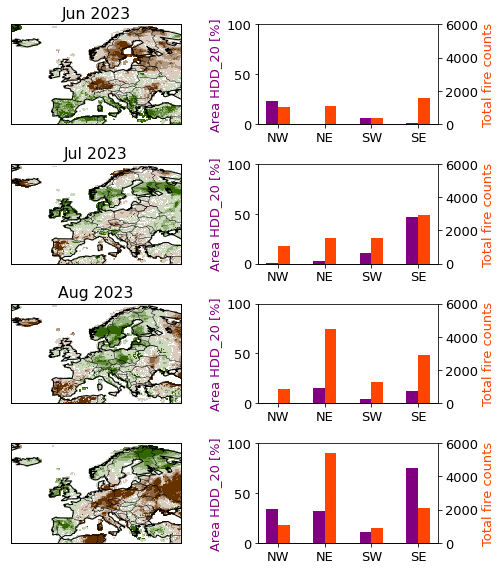

In [67]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.axes_divider import make_axes_area_auto_adjustable

fig, axs = plt.subplots(4, 2, figsize=(7.5,12), constrained_layout = True)
fig.tight_layout()
plt.subplots_adjust(left=0.1,
                    bottom=0.3, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)
#plt.show()

plot_type = "pcolormesh"
xlab="longitude ["+chr(176)+"]"
ylab="latitude ["+chr(176)+"]"
xlim=[-25, 40]
ylim=[34, 72]
zlim=[-3,3]
xlab=""
ylab=""
main_title=""
main_title=f"{ptime}"
legend_title=f"SPI-1"
colorscheme=cmap_spi
levels=clevels
legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3]
legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"]
ndays='N20'
purple_label="Area HDD_20 [%]"

# June
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-4]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[0,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - hot and dry days and fire activity
ax2 = axs[0,1].twinx()
bar1 = axs[0,1].bar([0,0.4,0.8,1.2], 
              [area_hdd_jun['Northwestern Europe'][ndays], 
               area_hdd_jun['Northeastern Europe'][ndays], 
               area_hdd_jun['Southwestern Europe'][ndays], 
               area_hdd_jun['Southeastern Europe'][ndays]], width = 0.1, color='purple')
#bar1 = axs[0,1].bar([0,0.4,0.8,1.2], 
#              [subregions_nhdd_jun['Northwestern Europe'], 
#               subregions_nhdd_jun['Northeastern Europe'], 
#               subregions_nhdd_jun['Southwestern Europe'], 
#               subregions_nhdd_jun['Southeastern Europe']], width = 0.1, color='purple')
bar2 = ax2.bar([0.1,0.5,0.9,1.3],
               [subregions_nfires_jun['Northwestern Europe'], 
               subregions_nfires_jun['Northeastern Europe'], 
               subregions_nfires_jun['Southwestern Europe'], 
               subregions_nfires_jun['Southeastern Europe']], width = 0.1, color='orangered')
axs[0,1].spines['top'].set_visible(False)
axs[0,1].spines['right'].set_visible(False)
axs[0,1].spines['bottom'].set_visible(True)
axs[0,1].spines['left'].set_visible(True)
axs[0,1].set_xticks([0.05,0.45,0.85,1.25])
axs[0,1].set_xticklabels(["NW","NE","SW","SE"])
axs[0,1].set_ylabel(purple_label, color='purple')
ax2.set_ylabel("Total fire counts", color='orangered')
#axs[0,1].set_ylim(0, 1750000)
axs[0,1].set_ylim(0, 100)
ax2.set_ylim(0, 6000)
axs[0,0].set_title("Jun 2023")


# July
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-3]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[1,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - hot and dry days and fire activity
ax2 = axs[1,1].twinx()
bar1 = axs[1,1].bar([0,0.4,0.8,1.2], 
              [area_hdd_jul['Northwestern Europe'][ndays], 
               area_hdd_jul['Northeastern Europe'][ndays], 
               area_hdd_jul['Southwestern Europe'][ndays], 
               area_hdd_jul['Southeastern Europe'][ndays]], width = 0.1, color='purple')
#bar1 = axs[1,1].bar([0,0.4,0.8,1.2], 
#              [subregions_nhdd_jul['Northwestern Europe'], 
#               subregions_nhdd_jul['Northeastern Europe'], 
#               subregions_nhdd_jul['Southwestern Europe'], 
#               subregions_nhdd_jul['Southeastern Europe']], width = 0.1, color='purple')
bar2 = ax2.bar([0.1,0.5,0.9,1.3],
               [subregions_nfires_jul['Northwestern Europe'], 
               subregions_nfires_jul['Northeastern Europe'], 
               subregions_nfires_jul['Southwestern Europe'], 
               subregions_nfires_jul['Southeastern Europe']], width = 0.1, color='orangered')
axs[1,1].spines['top'].set_visible(False)
axs[1,1].spines['right'].set_visible(False)
axs[1,1].spines['bottom'].set_visible(True)
axs[1,1].spines['left'].set_visible(True)
axs[1,1].set_xticks([0.05,0.45,0.85,1.25])
axs[1,1].set_xticklabels(["NW","NE","SW","SE"])
axs[1,1].set_ylabel(purple_label, color='purple')
ax2.set_ylabel("Total fire counts", color='orangered')
axs[1,1].set_ylim(0, 100)
ax2.set_ylim(0, 6000)
axs[1,0].set_title("Jul 2023")




# August
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-2]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[2,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)
axs[2,0].set_title("Aug 2023")

# - hot and dry days and fire activity
ax2 = axs[2,1].twinx()
bar1 = axs[2,1].bar([0,0.4,0.8,1.2], 
              [area_hdd_aug['Northwestern Europe'][ndays], 
               area_hdd_aug['Northeastern Europe'][ndays], 
               area_hdd_aug['Southwestern Europe'][ndays], 
               area_hdd_aug['Southeastern Europe'][ndays]], width = 0.1, color='purple')
#bar1 = axs[2,1].bar([0,0.4,0.8,1.2], 
#              [subregions_nhdd_aug['Northwestern Europe'], 
#               subregions_nhdd_aug['Northeastern Europe'], 
#               subregions_nhdd_aug['Southwestern Europe'], 
#               subregions_nhdd_aug['Southeastern Europe']], width = 0.1, color='purple')
bar2 = ax2.bar([0.1,0.5,0.9,1.3],
               [subregions_nfires_aug['Northwestern Europe'], 
               subregions_nfires_aug['Northeastern Europe'], 
               subregions_nfires_aug['Southwestern Europe'], 
               subregions_nfires_aug['Southeastern Europe']], width = 0.1, color='orangered')
axs[2,1].spines['top'].set_visible(False)
axs[2,1].spines['right'].set_visible(False)
axs[2,1].spines['bottom'].set_visible(True)
axs[2,1].spines['left'].set_visible(True)
axs[2,1].set_xticks([0.05,0.45,0.85,1.25])
axs[2,1].set_xticklabels(["NW","NE","SW","SE"])
axs[2,1].set_ylabel(purple_label, color='purple')
ax2.set_ylabel("Total fire counts", color='orangered')
axs[2,1].set_ylim(0, 100)
ax2.set_ylim(0, 6000)


# September
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-1]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[3,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - hot and dry days and fire activity
ax2 = axs[3,1].twinx()
bar1 = axs[3,1].bar([0,0.4,0.8,1.2], 
              [area_hdd_sep['Northwestern Europe'][ndays], 
               area_hdd_sep['Northeastern Europe'][ndays], 
               area_hdd_sep['Southwestern Europe'][ndays], 
               area_hdd_sep['Southeastern Europe'][ndays]], width = 0.1, color='purple')
#bar1 = axs[3,1].bar([0,0.4,0.8,1.2], 
#              [subregions_nhdd_sep['Northwestern Europe'], 
#               subregions_nhdd_sep['Northeastern Europe'], 
#               subregions_nhdd_sep['Southwestern Europe'], 
#               subregions_nhdd_sep['Southeastern Europe']], width = 0.1, color='purple')
bar2 = ax2.bar([0.1,0.5,0.9,1.3],
               [subregions_nfires_sep['Northwestern Europe'], 
               subregions_nfires_sep['Northeastern Europe'], 
               subregions_nfires_sep['Southwestern Europe'], 
               subregions_nfires_sep['Southeastern Europe']], width = 0.1, color='orangered')
axs[3,1].spines['top'].set_visible(False)
axs[3,1].spines['right'].set_visible(False)
axs[3,1].spines['bottom'].set_visible(True)
axs[3,1].spines['left'].set_visible(True)
axs[3,1].set_xticks([0.05,0.45,0.85,1.25])
axs[3,1].set_xticklabels(["NW","NE","SW","SE"])
axs[3,1].set_ylabel(purple_label, color='purple')
ax2.set_ylabel("Total fire counts", color='orangered')
axs[3,1].set_ylim(0, 100)
ax2.set_ylim(0, 6000)

plt.savefig(f"ESOTC2023_spotlight_drought_fire_hot_dry_days_{ndays}.png")

In [68]:
hdd10_index = {'Northern Europe': [area_hdd_jun['Northern Europe']['N10'], area_hdd_jul['Northern Europe']['N10'], area_hdd_aug['Northern Europe']['N10'], area_hdd_sep['Northern Europe']['N10']],
               'Southern Europe': [area_hdd_jun['Southern Europe']['N10'], area_hdd_jul['Southern Europe']['N10'], area_hdd_aug['Southern Europe']['N10'], area_hdd_sep['Southern Europe']['N10']]}
print(hdd10_index)
hdd15_index = {'Northern Europe': [area_hdd_jun['Northern Europe']['N15'], area_hdd_jul['Northern Europe']['N15'], area_hdd_aug['Northern Europe']['N15'], area_hdd_sep['Northern Europe']['N15']],
               'Southern Europe': [area_hdd_jun['Southern Europe']['N15'], area_hdd_jul['Southern Europe']['N15'], area_hdd_aug['Southern Europe']['N15'], area_hdd_sep['Southern Europe']['N15']]}
print(hdd15_index)

{'Northern Europe': [56.923700598280035, 26.39424906152337, 80.8982457881175, 91.03993493355544], 'Southern Europe': [52.35159565069507, 62.4894863613609, 63.48043011751783, 61.49830203790006]}
{'Northern Europe': [24.330604259279518, 9.47531310283512, 38.08141003393469, 76.18256093839523], 'Southern Europe': [23.01483582898846, 44.052591324114985, 39.25195791253032, 47.79089156877742]}


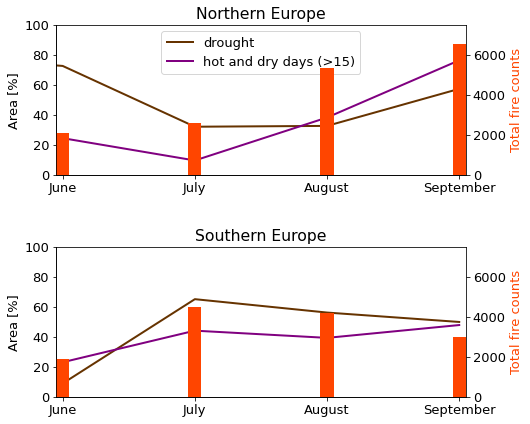

In [92]:
def plot_all_annual_cycles_north_south(aid_index, fire_index, hdd_index, selyear=2023, severity='any'):

    fig, (ax1,ax2) = plt.subplots(2, 1, sharex=False, figsize=(7.5,7))
    plt.setp([ax1,ax2], xticks=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], xticklabels=['J','F','M','A','M','June','July','August','September','O','N','D'])

    fig.tight_layout(pad=3.75)
    fig.subplots_adjust(top=0.875)
    font = {'family' : 'sans-serif',
            'weight' : 'normal',
            'size'   : 13}
    plt.rc('font', **font)

    regions = list(esotc_regions.keys())
    isev    = severity

    #for iyear in range(1991,2021):
    #    pidata = aid_index['Northern Europe'][isev].sel(time=aid_index['Northern Europe'][isev].time.dt.year.isin([iyear])).to_series() 
    #    ax1.plot(pidata.values, color='lightgrey', alpha=1)
    pidata = aid_index['Northern Europe'][isev].sel(time=aid_index['Northern Europe'][isev].time.dt.year.isin([selyear])).to_series()
    ax1.plot(pidata.values, color=color_list[0], alpha=1, linewidth=2, label='drought')
    ax1.set_ylabel("Area [%]")
    ax1.margins(x=0)
    ax1.set_title("Northern Europe")
    #ax1.bar([5.1, 6.1, 7.1, 8.1], hdd_index['Northern Europe'], width = 0.1, color='purple')
    ax1.plot([5, 6, 7, 8], hdd_index['Northern Europe'], linewidth = 2, color='purple', label = 'hot and dry days (>15)')
    ax1.legend(loc='upper center')
    ax11 = ax1.twinx()
    bar1 = ax11.bar([0, 1, 2, 3, 4, 5, 6, 7, 8], fire_index['Northern Europe'], width = 0.1, color='orangered')
    ax11.set_ylabel("Total fire counts", color='orangered')
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['bottom'].set_visible(True)
    ax1.spines['left'].set_visible(True)
    ax1.set_xlim([4.95,8.05])
    ax1.set_ylim([0,100])
    ax11.set_ylim([0,7500])

    #for iyear in range(1991,2021):
    #    pidata = aid_index['Southern Europe'][isev].sel(time=aid_index['Southern Europe'][isev].time.dt.year.isin([iyear])).to_series() 
    #    ax2.plot(pidata.values, color='lightgrey', alpha=1)
    pidata = aid_index['Southern Europe'][isev].sel(time=aid_index['Southern Europe'][isev].time.dt.year.isin([selyear])).to_series()
    ax2.plot(pidata.values, color=color_list[0], alpha=1, linewidth=2, label='drought')
    ax2.set_ylabel("Area [%]")
    ax2.margins(x=0)
    ax2.set_title("Southern Europe")
    #ax2.bar([5.1, 6.1, 7.1, 8.1], hdd_index['Southern Europe'], width = 0.1, color='purple')
    ax2.plot([5, 6, 7, 8], hdd_index['Southern Europe'], linewidth = 2, color='purple', label = 'hot and dry days (>15)')
    #ax2.legend()
    ax22 = ax2.twinx()
    bar2 = ax22.bar([0, 1, 2, 3, 4, 5, 6, 7, 8], fire_index['Southern Europe'], width = 0.1, color='orangered')
    ax22.set_ylabel("Total fire counts", color='orangered')
    #ax2.set_ylabel("Area HDD15 [%]", color='purple')
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.spines['bottom'].set_visible(True)
    ax2.spines['left'].set_visible(True)
    ax2.set_xlim([4.95,8.05])
    ax2.set_ylim([0,100])
    ax22.set_ylim([0,7500])

plot_all_annual_cycles_north_south(aid_spi1, subregions_nfires, hdd15_index, selyear=2023, severity='any')
#print(aid_spi1['Northern Europe']['any'])

In [ ]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.axes_divider import make_axes_area_auto_adjustable

fig, axs = plt.subplots(4, 2, figsize=(7.5,12), constrained_layout = True)
fig.tight_layout()
plt.subplots_adjust(left=0.1,
                    bottom=0.3, 
                    right=0.9, 
                    top=0.9, 
                    wspace=0.4, 
                    hspace=0.4)
#plt.show()

plot_type = "pcolormesh"
xlab="longitude ["+chr(176)+"]"
ylab="latitude ["+chr(176)+"]"
xlim=[-25, 40]
ylim=[34, 72]
zlim=[-3,3]
xlab=""
ylab=""
main_title=""
main_title=f"{ptime}"
legend_title=f"SPI-1"
colorscheme=cmap_spi
levels=clevels
legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3]
legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"]
ndays='N20'
purple_label="Area HDD_20 [%]"

# June
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-4]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[0,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - hot and dry days and fire activity
ax2 = axs[0,1].twinx()
bar1 = axs[0,1].bar([0,0.4,0.8,1.2], 
              [area_hdd_jun['Northwestern Europe'][ndays], 
               area_hdd_jun['Northeastern Europe'][ndays], 
               area_hdd_jun['Southwestern Europe'][ndays], 
               area_hdd_jun['Southeastern Europe'][ndays]], width = 0.1, color='purple')
#bar1 = axs[0,1].bar([0,0.4,0.8,1.2], 
#              [subregions_nhdd_jun['Northwestern Europe'], 
#               subregions_nhdd_jun['Northeastern Europe'], 
#               subregions_nhdd_jun['Southwestern Europe'], 
#               subregions_nhdd_jun['Southeastern Europe']], width = 0.1, color='purple')
bar2 = ax2.bar([0.1,0.5,0.9,1.3],
               [subregions_nfires_jun['Northwestern Europe'], 
               subregions_nfires_jun['Northeastern Europe'], 
               subregions_nfires_jun['Southwestern Europe'], 
               subregions_nfires_jun['Southeastern Europe']], width = 0.1, color='orangered')
axs[0,1].spines['top'].set_visible(False)
axs[0,1].spines['right'].set_visible(False)
axs[0,1].spines['bottom'].set_visible(True)
axs[0,1].spines['left'].set_visible(True)
axs[0,1].set_xticks([0.05,0.45,0.85,1.25])
axs[0,1].set_xticklabels(["NW","NE","SW","SE"])
axs[0,1].set_ylabel(purple_label, color='purple')
ax2.set_ylabel("Total fire counts", color='orangered')
#axs[0,1].set_ylim(0, 1750000)
axs[0,1].set_ylim(0, 100)
ax2.set_ylim(0, 6000)
axs[0,0].set_title("Jun 2023")


# July
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-3]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[1,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - hot and dry days and fire activity
ax2 = axs[1,1].twinx()
bar1 = axs[1,1].bar([0,0.4,0.8,1.2], 
              [area_hdd_jul['Northwestern Europe'][ndays], 
               area_hdd_jul['Northeastern Europe'][ndays], 
               area_hdd_jul['Southwestern Europe'][ndays], 
               area_hdd_jul['Southeastern Europe'][ndays]], width = 0.1, color='purple')
#bar1 = axs[1,1].bar([0,0.4,0.8,1.2], 
#              [subregions_nhdd_jul['Northwestern Europe'], 
#               subregions_nhdd_jul['Northeastern Europe'], 
#               subregions_nhdd_jul['Southwestern Europe'], 
#               subregions_nhdd_jul['Southeastern Europe']], width = 0.1, color='purple')
bar2 = ax2.bar([0.1,0.5,0.9,1.3],
               [subregions_nfires_jul['Northwestern Europe'], 
               subregions_nfires_jul['Northeastern Europe'], 
               subregions_nfires_jul['Southwestern Europe'], 
               subregions_nfires_jul['Southeastern Europe']], width = 0.1, color='orangered')
axs[1,1].spines['top'].set_visible(False)
axs[1,1].spines['right'].set_visible(False)
axs[1,1].spines['bottom'].set_visible(True)
axs[1,1].spines['left'].set_visible(True)
axs[1,1].set_xticks([0.05,0.45,0.85,1.25])
axs[1,1].set_xticklabels(["NW","NE","SW","SE"])
axs[1,1].set_ylabel(purple_label, color='purple')
ax2.set_ylabel("Total fire counts", color='orangered')
axs[1,1].set_ylim(0, 100)
ax2.set_ylim(0, 6000)
axs[1,0].set_title("Jul 2023")




# August
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-2]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[2,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)
axs[2,0].set_title("Aug 2023")

# - hot and dry days and fire activity
ax2 = axs[2,1].twinx()
bar1 = axs[2,1].bar([0,0.4,0.8,1.2], 
              [area_hdd_aug['Northwestern Europe'][ndays], 
               area_hdd_aug['Northeastern Europe'][ndays], 
               area_hdd_aug['Southwestern Europe'][ndays], 
               area_hdd_aug['Southeastern Europe'][ndays]], width = 0.1, color='purple')
#bar1 = axs[2,1].bar([0,0.4,0.8,1.2], 
#              [subregions_nhdd_aug['Northwestern Europe'], 
#               subregions_nhdd_aug['Northeastern Europe'], 
#               subregions_nhdd_aug['Southwestern Europe'], 
#               subregions_nhdd_aug['Southeastern Europe']], width = 0.1, color='purple')
bar2 = ax2.bar([0.1,0.5,0.9,1.3],
               [subregions_nfires_aug['Northwestern Europe'], 
               subregions_nfires_aug['Northeastern Europe'], 
               subregions_nfires_aug['Southwestern Europe'], 
               subregions_nfires_aug['Southeastern Europe']], width = 0.1, color='orangered')
axs[2,1].spines['top'].set_visible(False)
axs[2,1].spines['right'].set_visible(False)
axs[2,1].spines['bottom'].set_visible(True)
axs[2,1].spines['left'].set_visible(True)
axs[2,1].set_xticks([0.05,0.45,0.85,1.25])
axs[2,1].set_xticklabels(["NW","NE","SW","SE"])
axs[2,1].set_ylabel(purple_label, color='purple')
ax2.set_ylabel("Total fire counts", color='orangered')
axs[2,1].set_ylim(0, 100)
ax2.set_ylim(0, 6000)


# September
# - drought map
map_2d =  np.asarray(spi1.sel(time=spi1.time[-1]).values[:])
map_2d[map_2d <= zlim[0]] = zlim[0]
map_2d[map_2d >= zlim[1]] = zlim[1]
x, y = m(grid_lon, grid_lat)
map = Basemap(llcrnrlat=34, llcrnrlon=-25,
              urcrnrlat=72, urcrnrlon=40,
              projection='cyl', resolution='c', ax=axs[3,0])
#axs[0,0].set_ylim([34, 72])
#axs[0,0].set_xlim([-25,40])
map.drawcoastlines()
map.drawmapboundary()
map.drawcountries()
#map.plot([-25,40], [44, 44], color="black", linewidth=2, linestyle='dashed')
map.pcolormesh(x, y, map_2d, shading='auto', cmap=colorscheme, norm=levels)

# - hot and dry days and fire activity
ax2 = axs[3,1].twinx()
bar1 = axs[3,1].bar([0,0.4,0.8,1.2], 
              [area_hdd_sep['Northwestern Europe'][ndays], 
               area_hdd_sep['Northeastern Europe'][ndays], 
               area_hdd_sep['Southwestern Europe'][ndays], 
               area_hdd_sep['Southeastern Europe'][ndays]], width = 0.1, color='purple')
#bar1 = axs[3,1].bar([0,0.4,0.8,1.2], 
#              [subregions_nhdd_sep['Northwestern Europe'], 
#               subregions_nhdd_sep['Northeastern Europe'], 
#               subregions_nhdd_sep['Southwestern Europe'], 
#               subregions_nhdd_sep['Southeastern Europe']], width = 0.1, color='purple')
bar2 = ax2.bar([0.1,0.5,0.9,1.3],
               [subregions_nfires_sep['Northwestern Europe'], 
               subregions_nfires_sep['Northeastern Europe'], 
               subregions_nfires_sep['Southwestern Europe'], 
               subregions_nfires_sep['Southeastern Europe']], width = 0.1, color='orangered')
axs[3,1].spines['top'].set_visible(False)
axs[3,1].spines['right'].set_visible(False)
axs[3,1].spines['bottom'].set_visible(True)
axs[3,1].spines['left'].set_visible(True)
axs[3,1].set_xticks([0.05,0.45,0.85,1.25])
axs[3,1].set_xticklabels(["NW","NE","SW","SE"])
axs[3,1].set_ylabel(purple_label, color='purple')
ax2.set_ylabel("Total fire counts", color='orangered')
axs[3,1].set_ylim(0, 100)
ax2.set_ylim(0, 6000)

plt.savefig(f"ESOTC2023_spotlight_drought_fire_hot_dry_days_{ndays}.png")

## Add raw fire data

In [ ]:
rpath = "/perm/pajm/DATA/MODIS_MCD14ML/RAW/"

colnames = list(esotc_regions.keys())
colnames.insert(0,'date')
nfires = np.zeros((1,6))
nfires_gridded = np.zeros((1,6))

for yyyy in range(2023,2024):
    
    if yyyy >= 2023:
        mod = "061"
    else:
        mod = "006"
        
    for im in range(1,13):
    
        mm = str(im).zfill(2)
        print(f"Processing {yyyy}{mm}...")
        
        ifile = os.path.join(rpath,f"MCD14ML.{yyyy}{mm}.{mod}.03.txt")
        
        if not os.path.isfile(ifile):
            continue
            
        ffile  = pd.read_csv(ifile, sep=" ")
        #ffile  = ffile.drop(columns=['sat', 'T21', 'T31', 'sample', 'FRP', 'conf', 'type', 'dn'])

        dummy = []
        dummy.append(dt.datetime.strptime(str(yyyy)+str(mm), '%Y%m'))

        for iregion in esotc_regions.keys():

            ## raw data
            # simply counting the lines representing monthly fires, not masking for spurious data yet
            dfires = (ffile[ffile['lat'].between(esotc_regions[iregion]['extent'][0], esotc_regions[iregion]['extent'][1]) & 
                            ffile['lon'].between(esotc_regions[iregion]['extent'][2], esotc_regions[iregion]['extent'][3])]).shape[0]
            
            dummy.append(dfires)
            
        nfires = np.vstack((nfires, np.asarray(dummy)))

active_fires_df = pd.DataFrame(nfires[1:,:], columns=colnames)
active_fires_df['date'] = pd.to_datetime(active_fires_df['date'], format='%Y-%m-%d')
active_fires_df.set_index('date')

In [ ]:
gpath = "/home/nejk/code/esotc_drought/data_retrieval/esotc_active_fires/"

colnames = list(esotc_regions.keys())
colnames.insert(0,'date')
nfires_gridded = np.zeros((1,6))

for yyyy in range(2023,2024):
   
    for im in range(6,10):
    
        mm = str(im).zfill(2)
        print(f"Processing {yyyy}{mm}...")
        
        dummy = []
        dummy.append(dt.datetime.strptime(str(yyyy)+str(mm), '%Y%m'))

        for iregion in esotc_regions.keys():

            ## raw data
            # simply counting the lines representing monthly fires, not masking for spurious data yet
            #dfires = (ffile[ffile['lat'].between(esotc_regions[iregion]['extent'][0], esotc_regions[iregion]['extent'][1]) & 
            #                ffile['lon'].between(esotc_regions[iregion]['extent'][2], esotc_regions[iregion]['extent'][3])]).shape[0]
            #dummy.append(dfires)
            
            ## gridded data
            if iregion == "Europe":
                iregion_short = "europe"
            if iregion == "Northeast Europe":
                iregion_short = "neeurope"
            if iregion == "Northwest Europe":
                iregion_short = "nweurope"
            if iregion == "Southeast Europe":
                iregion_short = "seeurope"
            if iregion == "Southwest Europe":
                iregion_short = "sweurope"
                
            ifile   = os.path.join(gpath,f"ACTIVEint_FIRE_MAP_1KM_{yyyy}_{mm}_T_esotc_{iregion_short}.nc")
            content = xr.open_dataset(ifile)['ACTIVE_FIRE'].values[0][0][0]
            dummy.append(content)
            
        nfires_gridded = np.vstack((nfires_gridded, np.asarray(dummy)))

active_fires_gridded_df = pd.DataFrame(nfires_gridded[1:,:], columns=colnames)
active_fires_gridded_df['date'] = pd.to_datetime(active_fires_gridded_df['date'], format='%Y-%m-%d')
active_fires_gridded_df.set_index('date')

In [ ]:
active_fires_df

In [ ]:
plt.figure(figsize=(16,3))
#plt.plot(active_fires_df['date'][::-1], active_fires_df['Northwestern Europe'][::-1])
plt.plot(active_fires_df['date'], active_fires_df['Northwestern Europe'], label='Northwestern Europe')
plt.plot(active_fires_df['date'], active_fires_df['Northeastern Europe'], label='Northeastern Europe')
plt.plot(active_fires_df['date'], active_fires_df['Southwestern Europe'], label='Southwestern Europe')
plt.plot(active_fires_df['date'], active_fires_df['Southeastern Europe'], label='Southeastern Europe')
plt.legend(ncol=4)
plt.ylabel("Number of fires")
#print(active_fires_df['date','Southwestern Europe'])

In [ ]:
plt.figure(figsize=(16,5))
#plt.plot(active_fires_df['date'][::-1], active_fires_df['Northwestern Europe'][::-1])
plt.plot(active_fires_df['date'], active_fires_df['Northwestern Europe'], label='Northwestern Europe')
plt.plot(active_fires_df['date'], active_fires_df['Northeastern Europe'], label='Northeastern Europe')
plt.plot(active_fires_df['date'], active_fires_df['Southwestern Europe'], label='Southwestern Europe')
plt.plot(active_fires_df['date'], active_fires_df['Southeastern Europe'], label='Southeastern Europe')
plt.legend(ncol=4)
plt.ylabel("Number of fires")
plt.yscale('log')

In [ ]:
active_fires_df.drop(columns=['date','Europe']).plot.bar(stacked=True)
plt.ylabel("Number of fires")
plt.xticks(ticks=range(0,12),labels=["J","F","M","A","M","J","J","A","S","O","N","D"], rotation=0)
plt.xticks(range(0,12))
plt.xlim((-1,12))
plt.title("Fires in 2023")
#plt.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])